# Hidden riding regimes in NYC Citi Bike: a naive and a clock-aware HMM

**Team:** Jonathan Sy, Dennis Hantman, Nick Daniel, Maan Patel, Abhinav Sanisetty
**Course:** CSE 150A/250A, Probabilistic Reasoning and Learning

### The question
Every weekday, bikes flow out of residential neighbourhoods in the morning and pile up in job centres, so some stations sit empty while others overflow. The thing that drives this (whether the city is currently *commuting in*, *commuting out*, *riding for leisure*, or *staying home because it's raining*) is never recorded. We only see individual rides. That makes it a natural **latent-variable** problem:

> **Can a Hidden Markov Model recover hidden riding regimes from Citi Bike trip data, and does knowing the current regime help predict the next hour's flow of bikes between a residential area (the Upper East Side) and a job centre (Midtown)?**

### The two models in this notebook
| Model | Observation per hour | What we learned |
|---|---|---|
| **Naive HMM** | counts of 6 ride *types* (Upper East Side→Midtown, Midtown→Upper East Side, round trips, ...) | We hoped for commute-in, commute-out and leisure states. Instead the states are *busyness levels*: how much riding, not what kind. It also forecasts poorly, because it doesn't know what time it is. |
| **Clock-aware HMM** | same 6 counts, with emission rate = (hour-of-week average) × (state multiplier) | The clock explains the routine and the hidden state becomes a *level* relative to it, from ×0.15 to ×1.65, that tracks season, temperature and rain. It fits and forecasts much better, but the states are still about how much, not what kind. We implement Baum-Welch for this ourselves. |

The forecasts are compared against four simple baselines: the **hour-of-week average**, **persistence** (next hour = this hour), the **activity-adjusted average** (usual profile × how busy today has been so far) and the **24-hour ratio** (hour-of-week average × how busy the last 24 hours have been). Section 8 repeats the comparison for the clock-aware model over a full year of test months.

### How to run
1. `pip install hmmlearn pandas numpy scipy matplotlib pyarrow`
2. Run top to bottom. The first run downloads 24 months of trip data (~17 GB of zips) and caches a compact version, so later runs are fast. The walk-forward in section 8 holds ~92M rides as integers and refits the model 12 times; lower `WF_JOBS` on a small laptop.
3. Everything you might want to change lives in the **Config** cell.

In [1]:
import io, json, time, zipfile, urllib.request, warnings, logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import gammaln, logsumexp
from hmmlearn import hmm
from hmmlearn.base import ConvergenceMonitor
from sklearn.cluster import KMeans

logging.getLogger("hmmlearn").setLevel(logging.ERROR)   # silence "not converging" chatter; we check convergence ourselves
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

## 0. Config
* **Months**: Oct 2025 – Sep 2026. A full year covers every season, winter storms and all federal holidays.
* **Train/test split is by date, never random.** Shuffling hours would leak the future into training, and a time series has to be forecast forward. We train on Oct 2025 – Aug 2026 and test on **September 2026**, which includes Labor Day (Sep 7).
* **Full-year test (section 8).** One test month can't tell us how the model does across seasons, so section 8 tests **every month of Oct 2025 – Sep 2026**, training each time on only the 12 months before it. That needs 12 extra months of history (Oct 2024 – Sep 2025), used for training only.

In [2]:
MONTHS      = pd.period_range("2025-10", "2026-09", freq="M").strftime("%Y%m").tolist()   # YYYYMM, Citi Bike NYC monthly files
HISTORY_MONTHS = pd.period_range("2024-10", "2025-09", freq="M").strftime("%Y%m").tolist()   # extra training history for section 8
DATA_DIR    = Path("citibike-tripdata")     # raw zips + ride cache (gitignored)
TEST_START  = pd.Timestamp("2026-09-01")    # hours before this = train, from this on = test

# Zones: two fixed rectangles (lat min, lat max, lng min, lng max), minimum included and maximum excluded
RECTS = {"UES": (40.765, 40.790, -73.973, -73.945),    # Upper East Side: residential proxy
         "MID": (40.748, 40.762, -73.995, -73.967)}    # Midtown core: job-centre proxy
MIN_ENDPOINTS   = 100         # a zone station needs this many ride starts + ends in train ...
MIN_ACTIVE_DAYS = 30          # ... and rides starting on this many different days

K_RANGE_HMMLEARN = range(2, 9)   # hidden-state counts to try in the naive model
K_RANGE_CLOCK    = range(2, 7)   # ... and in the clock-aware model
N_RESTARTS       = 5             # EM is sensitive to initialisation, so try several seeds
SEED             = 150
HORIZONS         = range(1, 13)  # forecast 1..12 hours ahead
WF_JOBS          = 6             # parallel folds in section 8

DATA_DIR.mkdir(exist_ok=True)

## 1. Data sourcing
**Source:** Citi Bike System Data (https://citibikenyc.com/system-data), monthly zips in the public `tripdata` S3 bucket. Each row is one ride: `ride_id, rideable_type, started_at, ended_at, start/end station name + id, start/end lat/lng, member_casual`.

Quirks we handle:
* Monthly zips hold several CSV chunks, and some Citi Bike zips contain **nested zips**. We read every CSV recursively, straight from the zip (no extraction to disk), and **de-duplicate on `ride_id`** as a safeguard. It removed 0 rides from Oct 2024 – Sep 2025.
* Rides with a missing start or end station are dropped, since they can't be assigned to zones.
* We keep only the columns we need, so a full year (~45M rides) fits in memory.

In [3]:
BASE_URL = "https://s3.amazonaws.com/tripdata/{m}-citibike-tripdata.zip"

def download_month(m: str) -> Path:
    # Download to a .part file and rename only when complete, so an interrupted download is never mistaken for a
    # finished one. is_zipfile needs the directory at the END of the file, so it also catches truncated zips on disk.
    zip_path = DATA_DIR / f"{m}-citibike-tripdata.zip"
    if not zipfile.is_zipfile(zip_path):
        DATA_DIR.mkdir(exist_ok=True)
        part = zip_path.with_name(zip_path.name + ".part")
        print(f"downloading {BASE_URL.format(m=m)} ...")
        urllib.request.urlretrieve(BASE_URL.format(m=m), part)      # raises ContentTooShortError if cut off
        if not zipfile.is_zipfile(part):
            raise OSError(f"{part} is not a complete zip file; rerun to download it again")
        part.replace(zip_path)
    return zip_path

def iter_trip_csvs(zf: zipfile.ZipFile):
    # Yield (name, file object) for every CSV in a zip, including zips inside the zip, without extracting to disk.
    for name in zf.namelist():
        if name.startswith("__MACOSX") or name.endswith("/"):
            continue
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(zf.read(name))) as inner:
                yield from iter_trip_csvs(inner)
        elif name.lower().endswith(".csv"):
            with zf.open(name) as f:
                yield Path(name).name, f

month_zips = [download_month(m) for m in MONTHS]
for zp in month_zips:
    with zipfile.ZipFile(zp) as zf:
        print(zp.name, "->", sorted(name for name, _ in iter_trip_csvs(zf)))

202510-citibike-tripdata.zip -> ['202510-citibike-tripdata_1.csv', '202510-citibike-tripdata_2.csv', '202510-citibike-tripdata_3.csv', '202510-citibike-tripdata_4.csv', '202510-citibike-tripdata_5.csv']
202511-citibike-tripdata.zip -> ['202511-citibike-tripdata_1.csv', '202511-citibike-tripdata_2.csv', '202511-citibike-tripdata_3.csv', '202511-citibike-tripdata_4.csv']
202512-citibike-tripdata.zip -> ['202512-citibike-tripdata_1.csv', '202512-citibike-tripdata_2.csv', '202512-citibike-tripdata_3.csv']
202601-citibike-tripdata.zip -> ['202601-citibike-tripdata_1.csv', '202601-citibike-tripdata_2.csv']
202602-citibike-tripdata.zip -> ['202602-citibike-tripdata_1.csv', '202602-citibike-tripdata_2.csv']
202603-citibike-tripdata.zip -> ['202603-citibike-tripdata_1.csv', '202603-citibike-tripdata_2.csv', '202603-citibike-tripdata_3.csv']
202604-citibike-tripdata.zip -> ['202604-citibike-tripdata-part1.csv', '202604-citibike-tripdata-part2.csv', '202604-citibike-tripdata-part3.csv', '202604-c

In [4]:
try:
    import pyarrow  # noqa: F401
    STR = "string[pyarrow]"     # compact strings: ~5x less memory than Python objects
except ImportError:
    STR = "string"

NEEDED = {"ride_id", "started_at", "start_station_id", "end_station_id", "start_lat", "start_lng", "member_casual"}
def read_trip_csv(f, name: str):
    df = pd.read_csv(f, usecols=lambda c: c in NEEDED,
                     dtype={"ride_id": STR, "start_station_id": STR, "end_station_id": STR, "member_casual": STR})
    if not NEEDED.issubset(df.columns):
        print(f"  skipping {name}: unexpected columns {list(df.columns)}")
        return None, None
    df = df.dropna(subset=["started_at", "start_station_id", "end_station_id"])
    coords = df.groupby("start_station_id")[["start_lat", "start_lng"]].median()
    out = pd.DataFrame({
        "ride_id": df["ride_id"],
        "hour":    pd.to_datetime(df["started_at"], format="ISO8601").dt.floor("h"),
        "s":       df["start_station_id"],
        "e":       df["end_station_id"],
        "member":  df["member_casual"].eq("member").astype(bool),
    })
    return out, coords

def load_rides(months):
    # Compact rides + station coordinates for a list of months, from cache if we have it.
    tag = f"{months[0]}_{months[-1]}"     # cache name records the months, so changing them never reuses a stale cache
    rides_cache, coords_cache = DATA_DIR / f"rides_compact_{tag}.parquet", DATA_DIR / f"station_coords_{tag}.csv"
    if rides_cache.exists() and coords_cache.exists():
        print("loaded cache", tag)
        return pd.read_parquet(rides_cache), pd.read_csv(coords_cache, index_col=0, dtype={0: str})
    parts, coord_parts = [], []
    for zp in [download_month(m) for m in months]:
        with zipfile.ZipFile(zp) as zf:
            for name, f in iter_trip_csvs(zf):
                t0 = time.perf_counter()
                r, c = read_trip_csv(f, name)
                if r is not None:
                    parts.append(r); coord_parts.append(c)
                    print(f"  {name}: {len(r):,} rides ({time.perf_counter() - t0:.0f}s)")
    out = pd.concat(parts, ignore_index=True)
    n_raw = len(out)
    out = out.drop_duplicates("ride_id").drop(columns="ride_id").reset_index(drop=True)
    print(f"removed {n_raw - len(out):,} duplicate rides")
    coords = pd.concat(coord_parts).groupby(level=0).median()
    try:
        out.to_parquet(rides_cache); coords.to_csv(coords_cache)
    except Exception as ex:
        print("could not cache (install pyarrow for faster reruns):", ex)
    return out, coords

rides, station_coords = load_rides(MONTHS)

PERIOD_START = pd.Timestamp(MONTHS[0] + "01")
PERIOD_END   = (pd.Timestamp(MONTHS[-1] + "01") + pd.offsets.MonthBegin(1))
rides = rides[(rides.hour >= PERIOD_START) & (rides.hour < PERIOD_END)].reset_index(drop=True)
ALL_HOURS = pd.date_range(PERIOD_START, PERIOD_END, freq="h", inclusive="left")
is_test = ALL_HOURS >= TEST_START

print(f"{len(rides):,} rides, {rides.s.nunique():,} start stations, {len(ALL_HOURS)} hours "
      f"({(~is_test).sum()} train / {is_test.sum()} test)")
print(rides.groupby(rides.hour.dt.to_period("M")).size().rename("rides per month"))

loaded cache 202510_202609


45,226,940 rides, 2,490 start stations, 8760 hours (8040 train / 720 test)


hour
2025-10    4716616
2025-11    3406440
2025-12    2085222
2026-01    1806439
2026-02    1210761
2026-03    2934766
2026-04    3848169
2026-05    4681338
2026-06    5367824
2026-07    4975996
2026-08    5228178
2026-09    4965191
Freq: M, Name: rides per month, dtype: int64


**Sanity check.** Months range from 1.2M rides (February 2026) to 5.4M (June 2026): fewer in winter, more in summer (see the monthly totals above). Rides with a missing station are dropped, so these are not the official totals. If any month looks roughly double its neighbours, the de-duplication failed.

## 2. A first look: what does "obvious" structure look like?
Before modelling, we look at the patterns *everyone already knows*: the weekday double peak (8–9am, 5–6pm) and the weekend afternoon hump. Any model we build has to beat "just knowing this".

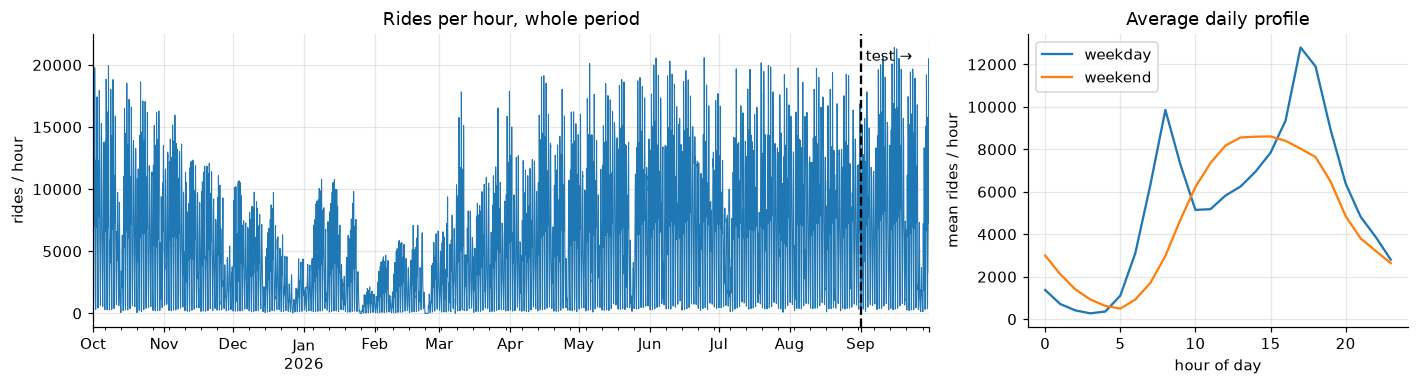

In [5]:
total = rides.groupby("hour").size().reindex(ALL_HOURS, fill_value=0)
members = rides.groupby("hour")["member"].sum().reindex(ALL_HOURS, fill_value=0)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
total.plot(ax=ax[0], lw=0.7)
ax[0].axvline(TEST_START, color="k", ls="--"); ax[0].text(TEST_START, total.max() * 0.95, " test →")
ax[0].set(title="Rides per hour, whole period", ylabel="rides / hour", xlabel="")

how = pd.DataFrame({"rides": total, "wkend": total.index.dayofweek >= 5, "h": total.index.hour})
for wk, g in how.groupby("wkend"):
    ax[1].plot(g.groupby("h").rides.mean(), label="weekend" if wk else "weekday")
ax[1].set(title="Average daily profile", xlabel="hour of day", ylabel="mean rides / hour"); ax[1].legend()
plt.tight_layout(); plt.show()

---
## 3. The naive model: an HMM on ride types
We first fit an ordinary HMM that does not know what time it is, and ask whether its states separate different *kinds* of riding.

### Zones: Upper East Side and Midtown
For rebalancing, the important thing is the **direction** of flow. We use two fixed map rectangles, drawn in advance rather than from the trip data:

* **UES (Upper East Side):** a mostly **residential** area
* **MID (Midtown core):** a **job centre**

A station belongs to a zone if it lies in the rectangle, has at least 100 ride starts + ends and has rides starting on at least 30 different days, all counted in the **training period only**. Every other station is outside both zones.

The labels come from the map and not from the trips, so a commuting pattern in the data is a finding. It is there: on weekdays the directional balance (UES→MID − MID→UES) / (UES→MID + MID→UES) averages **+0.49 at 7–10am** and **−0.33 at 4–7pm**.

*Caveats for the report:* "residential" and "job centre" describe the neighbourhoods, not the purpose of any ride. The UES rectangle also takes in five stations **west of Central Park**; they account for about 8% of the rides between the two zones.

zone
outside    2366
MID          70
UES          54
Name: stations per zone, dtype: int64


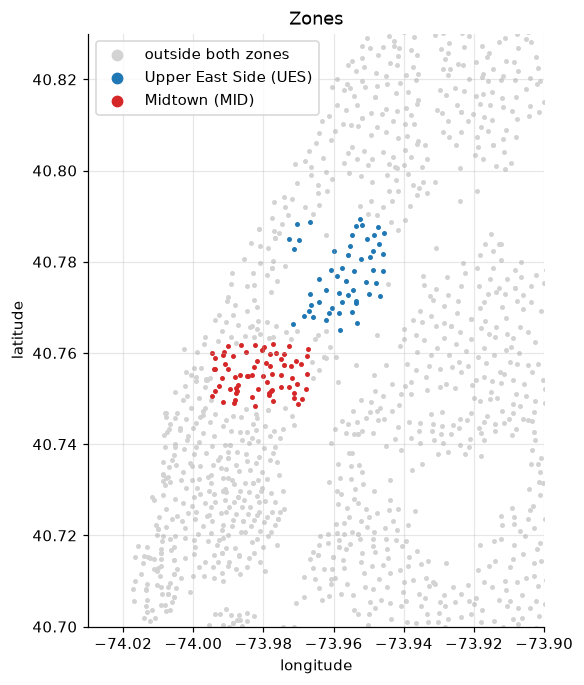

In [6]:
train_rides = rides[rides.hour < TEST_START]
ends = train_rides.s.value_counts().add(train_rides.e.value_counts(), fill_value=0)
active_days = train_rides.hour.dt.normalize().groupby(train_rides.s).nunique()
enough = (ends.reindex(station_coords.index).fillna(0) >= MIN_ENDPOINTS) & (active_days.reindex(station_coords.index).fillna(0) >= MIN_ACTIVE_DAYS)

coords = station_coords.assign(zone="outside")
for z, (lat0, lat1, lng0, lng1) in RECTS.items():
    inside = (coords.start_lat >= lat0) & (coords.start_lat < lat1) & (coords.start_lng >= lng0) & (coords.start_lng < lng1)
    coords.loc[inside & enough, "zone"] = z
zone_of = coords.zone.to_dict()
print(coords.zone.value_counts().rename("stations per zone"))

fig, ax = plt.subplots(figsize=(6, 7))
for z, c in [("outside", "lightgrey"), ("UES", "C0"), ("MID", "C3")]:
    g = coords[coords.zone == z]
    ax.scatter(g.start_lng, g.start_lat, s=5, c=c, label={"UES": "Upper East Side (UES)", "MID": "Midtown (MID)", "outside": "outside both zones"}[z])
ax.set(title="Zones", xlabel="longitude", ylabel="latitude", xlim=(-74.03, -73.90), ylim=(40.70, 40.83)); ax.legend(markerscale=3)
ax.set_aspect(1.3); plt.show()

**What the map shows.** Two non-overlapping groups of stations in Manhattan: 70 in Midtown and 54 in the UES rectangle, five of which are on the far (west) side of Central Park.

### Ride types (the observation vector)
Every ride gets exactly one type, checked in this order:
1. `round_trip`: start station = end station (often leisure); city-wide, not only in the two zones
2. `UES_to_MID`, `MID_to_UES`: the commuting directions
3. `within_UES`, `within_MID`: local trips inside one zone
4. `other`: everything else, i.e. any ride with an end outside both zones. Both zones are small, so **this is 93% of all rides**

Because the types are exhaustive, the six counts always sum to the total number of rides in the hour. **Member/casual is deliberately NOT an input.** We hold it out and use it afterwards to *validate* what the states mean. (We also never feed in a "commuter" label, because that would hand the model the answer.)

type
UES_to_MID    0.005
MID_to_UES    0.005
within_UES    0.015
within_MID    0.021
round_trip    0.020
other         0.933
Name: share of all rides, dtype: float64


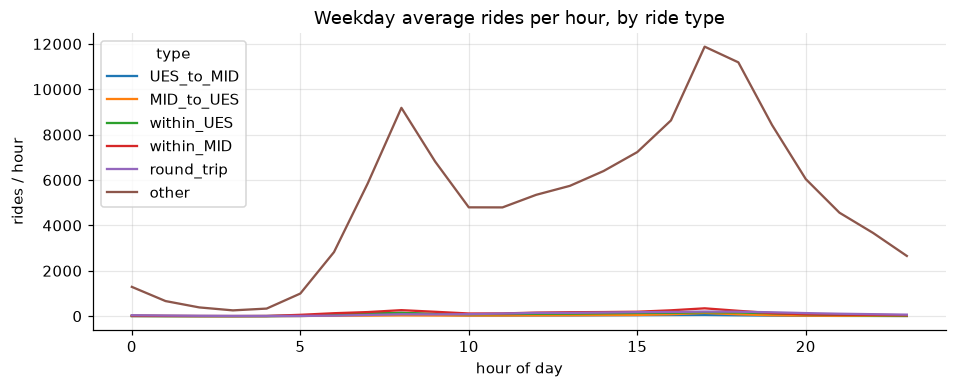

In [7]:
FEATURES = ["UES_to_MID", "MID_to_UES", "within_UES", "within_MID", "round_trip", "other"]
zs = rides.s.map(zone_of).fillna("outside").to_numpy(dtype=object)
ze = rides.e.map(zone_of).fillna("outside").to_numpy(dtype=object)
same = (rides.s == rides.e).to_numpy(dtype=bool)
rides["type"] = pd.Categorical(np.select(
    [same, (zs == "UES") & (ze == "MID"), (zs == "MID") & (ze == "UES"), (zs == "UES") & (ze == "UES"), (zs == "MID") & (ze == "MID")],
    ["round_trip", "UES_to_MID", "MID_to_UES", "within_UES", "within_MID"], default="other"), categories=FEATURES)

counts = (rides.groupby(["hour", "type"], observed=False).size().unstack(fill_value=0)
               .reindex(index=ALL_HOURS, columns=FEATURES, fill_value=0))
assert (counts.sum(axis=1).to_numpy() == total.to_numpy()).all()
print((counts.sum() / counts.to_numpy().sum()).rename("share of all rides").round(3))

wk = counts[counts.index.dayofweek < 5]
prof = wk.groupby(wk.index.hour).mean()
prof.plot(figsize=(10, 3.5), title="Weekday average rides per hour, by ride type")
plt.xlabel("hour of day"); plt.ylabel("rides / hour"); plt.show()

### The model
* Hidden state $z_t \in \{1,\dots,K\}$, one per hour, following a first-order Markov chain with start distribution $\pi$ and transition matrix $A_{ij} = P(z_{t+1}=j \mid z_t=i)$.
* Observation $x_t \in \mathbb{N}^6$ = the ride-type counts of hour $t$, with **independent Poisson emissions per ride type given the state**:
$$P(x_t \mid z_t=k) = \prod_{f=1}^{6} \text{Poisson}(x_{tf};\, \lambda_{kf}).$$
Each state has a *fingerprint*: how much of each kind of riding it produces. The model also assumes that **the six counts are independent given the regime**. This is plausible because the regime is what couples them (rush hour raises UES→MID *and* within_MID). But leftover correlation, e.g. from weather, would violate it.

**Why counts instead of shares (percentages)?** Shares are meaningless at 3am when there are only 4 rides. They also sum to 1, which makes a full-covariance Gaussian degenerate. Counts keep *both* volume and composition, and the Poisson naturally treats quiet hours as noisy.

**Why Poisson and not Gaussian?** $x_{tf}$ is a non-negative integer count, and Poisson is the standard distribution for "number of events in a time window". A Gaussian would put probability on negative and fractional ride counts.

### Independence assumptions (we need to state these in the report)
1. **Markov:** $z_{t+1} \perp z_{1:t-1} \mid z_t$. Only the current regime matters for the next one.
2. **Emission:** $x_t \perp$ everything else $\mid z_t$. Given the regime, this hour's count doesn't depend on past counts.
3. **Time-homogeneity:** $A$ is the same at 3am and at 8am. *This assumption is the one that will hurt us.*

### Learning and selection
* **Baum-Welch (EM)** via `hmmlearn.hmm.PoissonHMM`. The E-step runs forward-backward to get $P(z_t \mid x_{1:T})$. The M-step sets $\lambda_k$ to the posterior-weighted mean count and $A$ to the expected transition counts, normalised. EM only finds a *local* optimum, so we run **5 random restarts** and keep the best *training* log-likelihood.
* **Choosing K:** log-likelihood on September 2026 (elbow rule), plus BIC $= -2\log L + p\log T$ with $p = (K-1) + K(K-1) + KF$ free parameters. *Caveat:* in sections 3–7 September is used both to choose $K$ and to report results, so it is not a truly held-out month there. Section 8 chooses $K$ on training data only.

In [8]:
class FullHistoryMonitor(ConvergenceMonitor):
    # hmmlearn only keeps the last log-likelihoods; we want the whole curve for the convergence plots.
    def _reset(self):
        super()._reset(); self.full_history = []
    def report(self, log_prob):
        if not hasattr(self, "full_history"):
            self.full_history = []
        self.full_history.append(log_prob); super().report(log_prob)

def fit_poisson_hmm(X, K, seed, n_iter=500, tol=1e-2):
    # hmmlearn's default random lambdas can leave a state with zero posterior mass, which turns every
    # parameter into NaN (0/0 in the M-step). Instead, start each state at the mean of a k-means cluster
    # of log-counts, so every state owns some hours; the seed still varies the init across restarts.
    model = hmm.PoissonHMM(n_components=K, n_iter=n_iter, tol=tol, random_state=seed, init_params="st")
    labels = KMeans(K, n_init=1, random_state=seed).fit_predict(np.log1p(X))
    model.lambdas_ = np.array([X[labels == k].mean(axis=0) for k in range(K)]) + 1e-3
    model.monitor_ = FullHistoryMonitor(tol, n_iter, False)
    t0 = time.perf_counter(); model.fit(X); model.fit_seconds_ = time.perf_counter() - t0
    model.history_ = list(model.monitor_.full_history)
    return model

def n_params(K, F):
    return (K - 1) + K * (K - 1) + K * F

def run_sweep(fit_fn, score_fn, Ks, F, T_train, n_restarts=N_RESTARTS, label=""):
    # Fit every K with several seeds; keep, for each K, the restart with the best TRAIN log-likelihood.
    records, best = [], {}
    for K in Ks:
        for r in range(n_restarts):
            m = fit_fn(K, SEED + r)
            tr, te = score_fn(m, "train"), score_fn(m, "test")
            records.append(dict(K=K, restart=r, train_ll=tr, test_ll=te, iters=len(m.history_),
                                seconds=m.fit_seconds_, history=m.history_))
            if K not in best or tr > best[K][1]:
                best[K] = (m, tr)
        print(f"{label} K={K}: best train LL {best[K][1]:,.0f}")
    runs = pd.DataFrame(records)
    summ = (runs.loc[runs.groupby("K").train_ll.idxmax(), ["K", "train_ll", "test_ll", "iters", "seconds"]]
               .set_index("K"))
    summ["BIC"] = -2 * summ.train_ll + np.array([n_params(K, F) for K in summ.index]) * np.log(T_train)
    summ["test_ll_per_hour"] = summ.test_ll / is_test.sum()
    return {K: b[0] for K, b in best.items()}, runs, summ

def choose_K(summ, frac=0.9):
    # Smallest K that captures `frac` of the total held-out log-likelihood gain (an 'elbow' rule).
    gain = summ.test_ll - summ.test_ll.iloc[0]
    if gain.max() <= 0:
        return summ.index[0]
    return int(gain.index[gain >= frac * gain.max()][0])

def plot_sweep(summ, runs, title):
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
    ax[0].plot(summ.index, summ.test_ll_per_hour, "o-"); ax[0].set(title="Held-out log-lik per test hour", xlabel="K")
    ax[1].plot(summ.index, summ.BIC, "o-", color="C1"); ax[1].set(title="BIC on train (lower = better)", xlabel="K")
    for K, g in runs.groupby("K"):
        ax[2].scatter(np.full(len(g), K), g.train_ll - g.train_ll.max(), alpha=0.7)
    ax[2].set(title="Restarts: train LL minus best restart", xlabel="K", ylabel="Δ log-lik")
    fig.suptitle(title); plt.tight_layout(); plt.show()

naive K=2: best train LL -4,838,388


naive K=3: best train LL -2,526,035


naive K=4: best train LL -1,622,197


naive K=5: best train LL -1,190,831


naive K=6: best train LL -950,385


naive K=7: best train LL -806,710


naive K=8: best train LL -710,576


,test_ll,iters,seconds,BIC,test_ll_per_hour
K,,,,,
2,-531771.084,13,0.043,9.677e+06,-738.571
3,-290144.989,31,0.150,5.052e+06,-402.979
4,-183891.753,45,0.285,3.245e+06,-255.405
5,-140847.112,41,0.328,2.382e+06,-195.621
6,-104657.354,77,0.747,1.901e+06,-145.357
7,-93666.254,71,0.847,1.614e+06,-130.092
8,-77721.281,230,3.134,1.422e+06,-107.946


BIC-optimal K: 8 | elbow-chosen K: 6


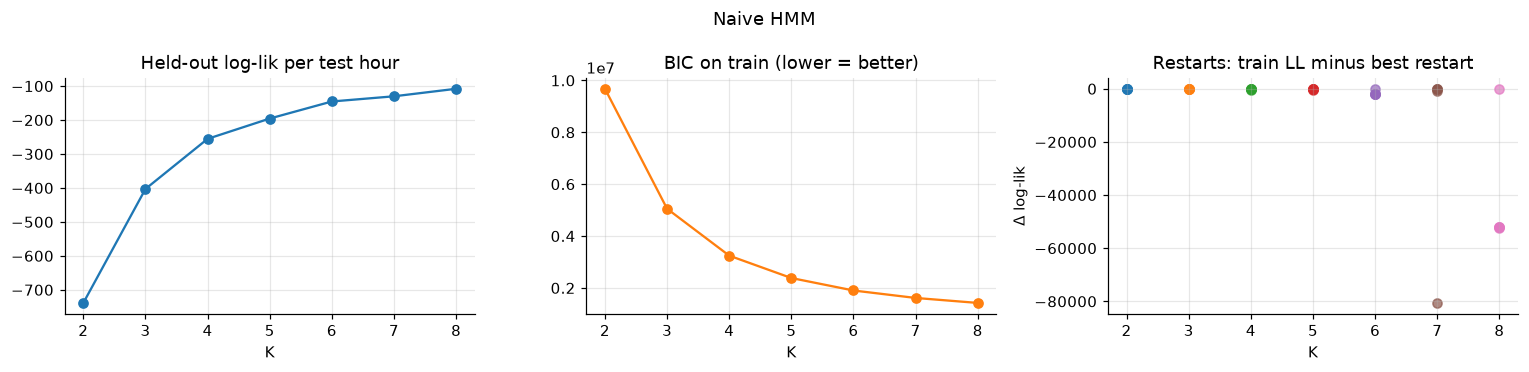

In [9]:
X_all = counts.to_numpy().astype(int)        # (T, 6)
X_tr, X_te = X_all[~is_test], X_all[is_test]

models_naive, runs_naive, summ_naive = run_sweep(
    fit_fn=lambda K, s: fit_poisson_hmm(X_tr, K, s),
    score_fn=lambda m, part: m.score(X_tr if part == "train" else X_te),
    Ks=K_RANGE_HMMLEARN, F=len(FEATURES), T_train=len(X_tr), label="naive")
K_naive = choose_K(summ_naive)
display(summ_naive.drop(columns=["train_ll"]))
print("BIC-optimal K:", summ_naive.BIC.idxmin(), "| elbow-chosen K:", K_naive)
plot_sweep(summ_naive, runs_naive, "Naive HMM")

**How to read this.** With counts in the hundreds or thousands per hour, real data is far *more variable* than a single Poisson allows (overdispersion: a Poisson's variance equals its mean). The model compensates by adding states that cut the count range into finer slices, so BIC and held-out likelihood often keep improving as K grows. That is itself a finding: *more states ≠ more meaning*. We pick K with the elbow rule and then check whether the states mean anything.

In [10]:
def relabel_by(values):
    # Return a mapping old_state -> new_state so that new labels are sorted by `values` (ascending).
    order = np.argsort(values); rank = np.empty_like(order); rank[order] = np.arange(len(order)); return rank

def occupancy_heatmap(states, K, title, names=None):
    # Fraction of hours of each hour-of-day assigned to each state, weekday vs weekend.
    df = pd.DataFrame({"z": states, "h": ALL_HOURS.hour, "wk": ALL_HOURS.dayofweek >= 5})
    fig, axes = plt.subplots(1, 2, figsize=(13, 0.45 * K + 1.6), sharey=True)
    for ax, (wk, g) in zip(axes, df.groupby("wk")):
        occ = pd.crosstab(g.z, g.h, normalize="columns").reindex(range(K), fill_value=0)
        im = ax.imshow(occ, aspect="auto", cmap="Blues", vmin=0, vmax=1)
        ax.set(title=("weekend" if wk else "weekday"), xlabel="hour of day", xticks=range(0, 24, 3))
        ax.grid(False)
    axes[0].set_yticks(range(K), names if names is not None else [f"state {k}" for k in range(K)])
    fig.colorbar(im, ax=axes, label="share of hours in state", fraction=0.025)
    fig.suptitle(title); plt.show()

,UES_to_MID,MID_to_UES,within_UES,within_MID,round_trip,other,total rides/h,member share (held out)
"S0: 409/h, most over-rep: round_trip",0.47,0.63,0.83,1.12,1.43,1.00,409.10,0.81
"S1: 1,554/h, most over-rep: within_MID",0.68,0.80,1.05,1.14,1.10,1.00,1554.36,0.84
"S2: 3,718/h, most over-rep: within_MID",0.92,0.86,1.10,1.10,0.93,1.00,3718.01,0.86
"S3: 6,549/h, most over-rep: within_UES",1.02,0.92,1.06,1.02,0.99,1.00,6549.47,0.84
"S4: 9,748/h, most over-rep: UES_to_MID",1.12,0.99,1.02,0.99,1.00,1.00,9747.62,0.82
"S5: 14,631/h, most over-rep: MID_to_UES",1.00,1.25,0.93,0.92,1.00,1.00,14631.05,0.81


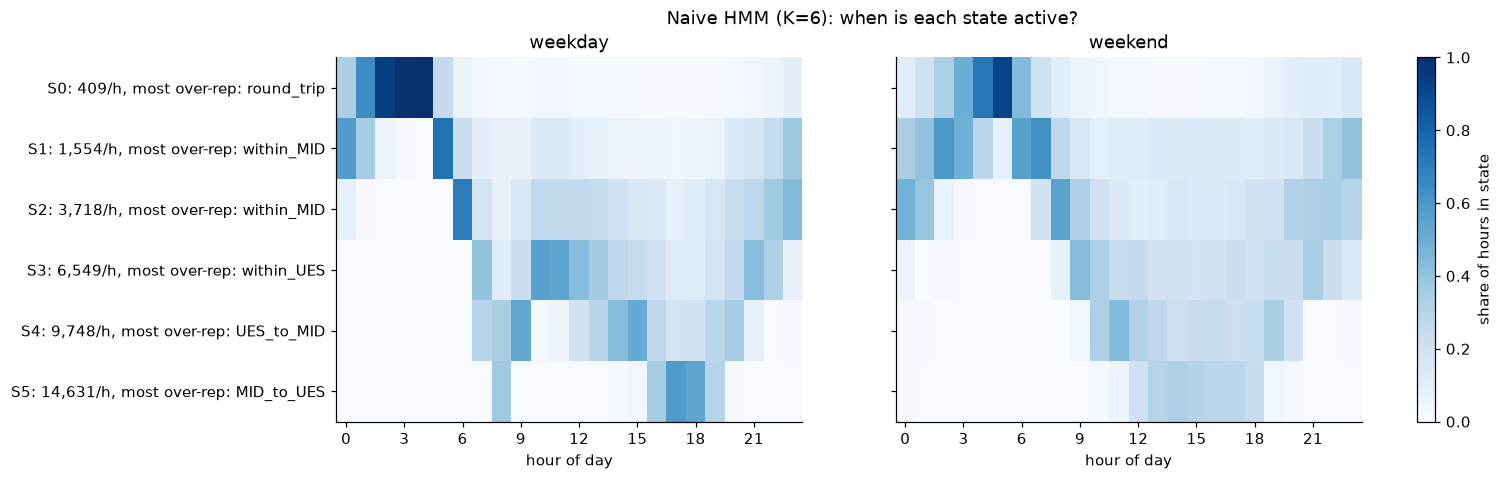

In [11]:
m_naive = models_naive[K_naive]
lam_naive = m_naive.lambdas_                                          # (K, 6)
rank_naive = relabel_by(lam_naive.sum(1))
lam_naive = lam_naive[np.argsort(lam_naive.sum(1))]
z_naive = rank_naive[m_naive.predict(X_all)]

share = lam_naive / lam_naive.sum(1, keepdims=True)
overall = X_all.sum(0) / X_all.sum()
lift = share / overall                                      # >1 = over-represented in this state
member_share = pd.Series(members.to_numpy()).groupby(z_naive).sum() / pd.Series(total.to_numpy()).groupby(z_naive).sum()

def auto_name(k):
    top = FEATURES[int(np.argmax(lift[k]))]
    return f"S{k}: {lam_naive[k].sum():,.0f}/h, most over-rep: {top}"
names_naive = [auto_name(k) for k in range(K_naive)]

fp = pd.DataFrame(lift, columns=FEATURES, index=names_naive)
fp["total rides/h"] = lam_naive.sum(1); fp["member share (held out)"] = member_share.reindex(range(K_naive)).to_numpy()
display(fp.style.background_gradient(cmap="RdBu_r", subset=FEATURES, vmin=0, vmax=2).format("{:.2f}"))
occupancy_heatmap(z_naive, K_naive, f"Naive HMM (K={K_naive}): when is each state active?", names_naive)

**What the fingerprint table shows.** Each cell is the *lift*: a ride type's share inside the state divided by its overall share. A value of 2.0 means "twice as common as usual". We hoped to find commute-in, commute-out and leisure states. **We did not:**
* **No commute-in state.** The highest UES_to_MID lift is 1.12. Real weekday 7–10am hours have a lift of 2.36, but they are spread over all six states.
* **No commute-out state.** The highest MID_to_UES lift is 1.25, in the busiest state. Real weekday 4–7pm hours have a lift of 1.68.
* **No leisure state.** The highest round_trip lift is 1.43, in the quietest state, which is mostly 1–5am.
* What sorts the states is **volume**, from 409 to 14,631 rides per hour: they are **busyness levels**. The busiest is most common around 4–7pm and 8am, and the quietest between 1am and 5am. They are not only the daily profile, though, because how busy an hour is also depends on the season and the day.

**Member share** was never shown to the model, and it doesn't support reading the states as trip purposes: it is 0.81–0.86 in every state. It does vary between real hours (0.905 on weekdays at 7–10am, 0.753 on weekend afternoons), so the states miss that difference.

### The states in one picture
Each dot is an hour, plotted by volume (x) and **directional balance** (y) = (UES→MID − MID→UES)/(UES→MID + MID→UES + 1). The states are vertical bands: they split hours by volume and not by direction.

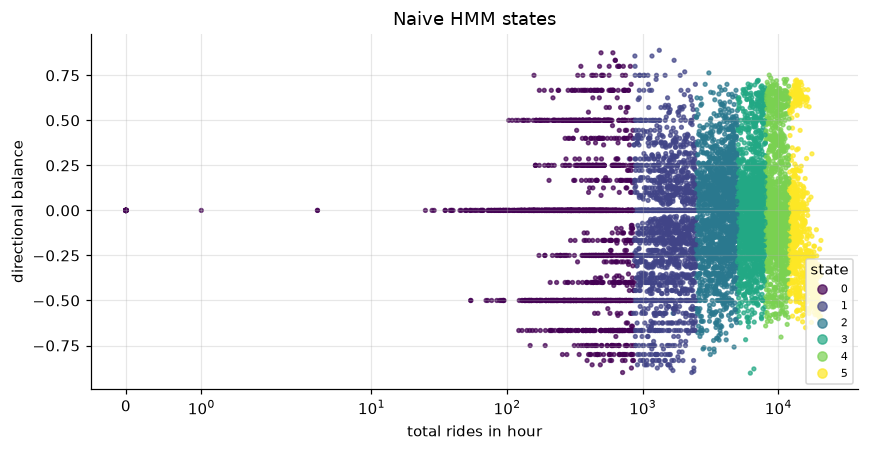

In [12]:
bal = (counts.UES_to_MID - counts.MID_to_UES) / (counts.UES_to_MID + counts.MID_to_UES + 1)
fig, ax = plt.subplots(figsize=(8, 4.2))
sc = ax.scatter(total, bal, c=z_naive, cmap="viridis", s=6, alpha=0.7, vmin=0, vmax=K_naive - 1)
ax.set(title="Naive HMM states", xlabel="total rides in hour", ylabel="directional balance"); ax.set_xscale("symlog")
ax.legend(*sc.legend_elements(), title="state", fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

---
## 4. Inference by hand: forward filtering and Viterbi
To forecast, we need **filtering**, $P(z_t \mid x_{1:t})$, which uses only the past. `hmmlearn.predict_proba` returns *smoothed* posteriors $P(z_t \mid x_{1:T})$, which use the future and would be cheating for forecasting. So we implement the **forward algorithm** ourselves:

$$\alpha_1(k) \propto \pi_k\, p(x_1 \mid k), \qquad \alpha_t(k) \propto \Big[\sum_j \alpha_{t-1}(j) A_{jk}\Big]\, p(x_t \mid k)$$

We work in log space (log-sum-exp) and normalise $\alpha_t$ at every step to avoid numerical underflow. The log normalisers summed over time are exactly $\log P(x_{1:T})$, which lets us **verify our implementation** against `hmmlearn.score`.

**Forecasting h hours ahead:** $P(z_{t+h} \mid x_{1:t}) = \alpha_t A^h$, and $\mathbb{E}[x_{t+h} \mid x_{1:t}] = \sum_k P(z_{t+h}=k \mid x_{1:t})\, \lambda_k$. As $h$ grows, $\alpha_t A^h$ converges to the stationary distribution of $A$, so long-range forecasts flatten toward a constant. That is another reason the naive HMM struggles.

**Viterbi** (max-product instead of sum-product) gives the single most likely state *path*. We implement it too and check it against `hmmlearn.decode`.

In [13]:
def poisson_log_emissions(X, lam):
    # log p(x_t | z_t=k) for independent Poisson features. X: (T,F), lam: (K,F) or (T,K,F) -> (T,K)
    lam = np.maximum(lam, 1e-10)
    if lam.ndim == 2:
        lam = lam[None]
    return (X[:, None, :] * np.log(lam) - lam - gammaln(X + 1)[:, None, :]).sum(-1)

def forward_filter(logB, startprob, transmat):
    # Forward algorithm in log space. Returns filt[t] = P(z_t | x_1..t) and log P(x_1..T).
    # With thousands of rides per hour, states' emission log-likelihoods differ by thousands of nats, so a
    # state's prior can underflow below 1e-300 after an abrupt change (e.g. a snowstorm shutdown). Keeping the
    # prior as a log (via logsumexp) avoids that; flooring it at 1e-300 would overstate log P(x).
    T, K = logB.shape
    with np.errstate(divide="ignore"):
        log_prior, logA = np.log(startprob), np.log(transmat)
    filt, loglik = np.empty((T, K)), 0.0
    for t in range(T):
        lw = log_prior + logB[t]
        norm = logsumexp(lw)
        loglik += norm
        log_filt = lw - norm
        filt[t] = np.exp(log_filt)
        log_prior = logsumexp(log_filt[:, None] + logA, axis=0)
    return filt, loglik

def viterbi(logB, startprob, transmat):
    T, K = logB.shape
    with np.errstate(divide="ignore"):             # log 0 = -inf: an impossible move stays impossible
        log_start, logA = np.log(startprob), np.log(transmat)
    delta = log_start + logB[0]; back = np.zeros((T, K), dtype=int)
    for t in range(1, T):
        cand = delta[:, None] + logA                 # (from, to)
        back[t] = cand.argmax(0); delta = cand.max(0) + logB[t]
    path = np.empty(T, dtype=int); path[-1] = delta.argmax()
    for t in range(T - 1, 0, -1):
        path[t - 1] = back[t, path[t]]
    return path

# --- verify our implementations against hmmlearn on the naive model
logB_naive = poisson_log_emissions(X_all.astype(float), m_naive.lambdas_)
filt_naive, ll_ours = forward_filter(logB_naive, m_naive.startprob_, m_naive.transmat_)
print(f"log P(x) ours = {ll_ours:,.3f}   hmmlearn = {m_naive.score(X_all):,.3f}")
assert np.isclose(ll_ours, m_naive.score(X_all), rtol=1e-6)
agree = (viterbi(logB_naive, m_naive.startprob_, m_naive.transmat_) == m_naive.predict(X_all)).mean()
print(f"Viterbi path agreement with hmmlearn: {agree:.1%}")

log P(x) ours = -1,053,727.022   hmmlearn = -1,053,727.022
Viterbi path agreement with hmmlearn: 100.0%


## 5. Does knowing the regime help forecasting? (Naive model vs baselines)
**Targets in September 2026** (the month also used to choose $K$, see section 3):
* total rides next hour
* `UES_to_MID` and `MID_to_UES` next hour
* **net flow into Midtown** = UES_to_MID − MID_to_UES. This is the quantity that empties Upper East Side docks and fills Midtown ones, so it's the one rebalancing acts on.

**Methods:**
* **Hour-of-week mean:** average of the train weeks for the same weekday and hour. Knows the clock, ignores the present.
* **Persistence:** next hour = this hour. Knows the present, ignores the clock.
* **Activity-adjusted:** the usual weekday/weekend hourly profile × today's busyness so far (rides so far today ÷ usual rides by this time). The ratio is 1 when nothing of today has been seen yet. Knows the clock *and* the present, with no hidden state.
* **24-hour ratio:** the hour-of-week mean × (rides in the last 24 hours ÷ usual rides in those hours). Like activity-adjusted, but it does **not** reset at midnight. No hidden state, so it separates "carrying the current level forward" from "having a hidden state".
* **Naive HMM:** forward-filter on everything up to $t-h$, propagate $h$ steps, then take the expected emission.

**Metric:** mean absolute error (MAE), in rides per hour.

**What we found** (MAE; the output below is $h=1$, the 2-hour result comes from section 7).
* **Total rides:** at $h=1$ the naive HMM beats the hour-of-week mean (1,912 vs 2,448) but not persistence (1,767). From $h=2$ it loses to the hour-of-week mean.
* **Direction and net flow:** the naive HMM already loses to the hour-of-week mean at $h=1$ (UES→MID 22.3 vs 13.3, net flow 21.4 vs 11.0). It is worse than persistence on both directions and about equal on net flow.
* **Activity-adjusted** and the **24-hour ratio** are the two best of these methods on every target at $h=1$. Activity-adjusted is ahead on total rides and UES→MID, the ratio on MID→UES and net flow.

The naive HMM has no idea that "8am is coming" beyond the transition matrix. That motivates the clock-aware model.

In [14]:
how_key = lambda idx: idx.dayofweek * 24 + idx.hour
train_counts = counts[~is_test]
how_means = train_counts.groupby(how_key(train_counts.index)).mean()
B_how = how_means.reindex(how_key(ALL_HOURS)).to_numpy()          # (T, 6) clock baseline for every hour

def targets(F6):
    # Map a (T,6) array of ride-type forecasts/actuals to the evaluation targets.
    F6 = np.asarray(F6, float)
    return {"total": F6.sum(1), "UES_to_MID": F6[:, 0], "MID_to_UES": F6[:, 1], "net_into_MID": F6[:, 0] - F6[:, 1]}

def hmm_forecast(filt, transmat, rate_fn, h):
    P = np.full_like(filt, np.nan)
    P[h:] = filt[:-h] @ np.linalg.matrix_power(transmat, h)     # P(z_t | x_1..t-h)
    return rate_fn(P)

def persistence(X, h):
    out = np.full(X.shape, np.nan); out[h:] = X[:-h]; return out

def activity_adjusted(X, h, train_mask, hours, ratio_cols=slice(None)):
    # Forecast for hour t made h hours earlier: weekday/weekend profile * (rides so far today / usual rides so far).
    X, wk, hr = np.asarray(X, float), (hours.dayofweek >= 5).astype(int), hours.hour.to_numpy()
    prof = np.stack([[X[train_mask & (wk == g) & (hr == k)].mean(0) for k in range(24)] for g in (0, 1)])   # (2, 24, F)
    usual = np.concatenate([np.zeros((2, 1)), prof[:, :, ratio_cols].sum(-1).cumsum(1)], axis=1)
    days = X[:, ratio_cols].sum(1).reshape(-1, 24)
    seen = np.concatenate([np.zeros((len(days), 1)), days.cumsum(1)], axis=1)
    c = np.maximum(hr - h + 1, 0)                                 # hours of today seen when the forecast is issued
    ob, ex = seen[np.arange(len(X)) // 24, c], usual[wk, c]
    ratio = np.divide(ob, ex, out=np.ones_like(ob), where=(c > 0) & (ex > 0))
    return ratio[:, None] * prof[wk, hr]

def ratio_24h(X, B, h, ratio_cols=slice(None)):
    # Forecast for hour t made h hours earlier: clock baseline * (rides in the last 24 hours / usual rides in those hours).
    X, B = np.asarray(X, float), np.asarray(B, float)
    last24 = lambda A: pd.Series(A[:, ratio_cols].sum(1)).rolling(24).sum().shift(h).to_numpy()
    ob, ex = last24(X), last24(B)
    ratio = np.divide(ob, ex, out=np.full_like(ob, np.nan), where=ex > 0)      # NaN until a full 24 hours have been seen
    return ratio[:, None] * B

actual = targets(X_all)

def evaluate(forecasters, horizons):
    rows = []
    for h in horizons:
        for name, fn in forecasters.items():
            pred = fn(h)
            for tgt, y in actual.items():
                if tgt in pred:
                    rows.append(dict(h=h, method=name, target=tgt, MAE=np.nanmean(np.abs(pred[tgt][is_test] - y[is_test]))))
    return pd.DataFrame(rows)

forecasters = {
    "hour-of-week mean": lambda h: targets(B_how),
    "persistence":       lambda h: targets(persistence(X_all, h)),
    "activity-adjusted": lambda h: targets(activity_adjusted(X_all, h, ~is_test, ALL_HOURS)),
    "24h ratio":         lambda h: targets(ratio_24h(X_all, B_how, h)),
    "naive HMM": lambda h: targets(hmm_forecast(filt_naive, m_naive.transmat_, lambda P: P @ m_naive.lambdas_, h)),
}
res_naive = evaluate(forecasters, HORIZONS)
display(res_naive[res_naive.h == 1].pivot(index="method", columns="target", values="MAE")[list(actual)].round(1))

target,total,UES_to_MID,MID_to_UES,net_into_MID
method,,,,
24h ratio,898.0,8.0,7.7,8.8
activity-adjusted,844.4,7.5,7.9,9.6
hour-of-week mean,2447.7,13.3,13.3,11.0
naive HMM,1912.3,22.3,20.7,21.4
persistence,1766.6,17.0,16.0,21.5


---
## 6. The clock-aware model (our own Baum-Welch)

### The diagnosis
The naive model's states are volume levels. Volume mixes the daily cycle, which the calendar gives us for free, with how busy that day or season is. What the calendar **can't** tell us is whether *today* is unusual: rain, a holiday, a heat wave, an event. That deviation is the truly hidden part.

### The model
Keep the 6 ride-type counts, and let the hidden state act as a **multiplier on the clock baseline** $b_{tf}$ (the hour-of-week mean from training):
$$x_{tf} \mid z_t = k \;\sim\; \text{Poisson}(b_{tf}\, m_{kf})$$
* $m_{kf}=1$: riding is normal for this time of week
* $m_{kf}=0.5$: half the usual riding of type $f$
* different $m$ for different types: an hour with an unusual *mix* (for example low UES_to_MID and high round_trip on a holiday). The model allows this, but the fitted states don't show it (see below).

The Markov chain over $z_t$ captures that unusual conditions **persist** for several hours. The independence assumptions are unchanged, except that the emission now depends on the known clock $b_t$ as well as on $z_t$.

### Learning it: Baum-Welch derived for this model
`hmmlearn` can't express "rate = known baseline × state multiplier", so we implement EM ourselves:
* **E-step:** scaled forward-backward gives $\gamma_t(k) = P(z_t=k \mid x_{1:T})$ and the expected transition counts $\sum_t \xi_t(j,k)$.
* **M-step:** $\pi = \gamma_1$, and $A_{jk} \propto \sum_t \xi_t(j,k)$. Setting the derivative of the expected complete-data log-likelihood with respect to $m_{kf}$ to zero gives a closed form:
$$m_{kf} = \frac{\sum_t \gamma_t(k)\, x_{tf}}{\sum_t \gamma_t(k)\, b_{tf}}$$
i.e. "observed rides ÷ expected rides", weighted by how much each hour belongs to state $k$.

EM guarantees the log-likelihood **never decreases**, so we assert this as a correctness check on our implementation.

In [15]:
class ClockAwarePoissonHMM:
    # x_tf | z_t=k ~ Poisson(B_tf * m_kf), with z_t a first-order Markov chain. Fit by Baum-Welch (EM).

    def __init__(self, n_components, n_iter=300, tol=1e-2, random_state=0):
        self.K, self.n_iter, self.tol, self.random_state = n_components, n_iter, tol, random_state

    def _init(self, X, B):
        rng = np.random.default_rng(self.random_state)
        K, F = self.K, X.shape[1]
        ratio = X.sum(1) / B.sum(1)
        levels = np.quantile(ratio, (np.arange(K) + 0.5) / K)          # spread initial multipliers over observed ratios
        self.multipliers_ = levels[:, None] * rng.uniform(0.85, 1.15, (K, F))
        self.startprob_ = np.full(K, 1 / K)
        A = rng.uniform(0.5, 1.5, (K, K)) + 5 * K * np.eye(K)          # sticky start: regimes persist
        self.transmat_ = A / A.sum(1, keepdims=True)

    def log_emissions(self, X, B):
        return poisson_log_emissions(X, B[:, None, :] * self.multipliers_[None, :, :])

    def _forward_backward(self, logB):
        T, K = logB.shape; A = self.transmat_
        mx = logB.max(1, keepdims=True); b = np.exp(logB - mx)        # per-row rescaling for numerical stability
        alpha, c = np.empty((T, K)), np.empty(T)
        alpha[0] = self.startprob_ * b[0]; c[0] = alpha[0].sum(); alpha[0] /= c[0]
        for t in range(1, T):
            alpha[t] = (alpha[t - 1] @ A) * b[t]; c[t] = alpha[t].sum(); alpha[t] /= c[t]
        beta = np.ones((T, K))
        for t in range(T - 2, -1, -1):
            beta[t] = A @ (b[t + 1] * beta[t + 1]) / c[t + 1]
        gamma = alpha * beta; gamma /= gamma.sum(1, keepdims=True)
        xi_sum = A * (alpha[:-1].T @ (b[1:] * beta[1:] / c[1:, None]))
        return gamma, xi_sum, np.log(c).sum() + mx.sum()

    def fit(self, X, B):
        X, B = np.asarray(X, float), np.maximum(np.asarray(B, float), 1e-3)
        self._init(X, B); self.history_ = []
        t0 = time.perf_counter()
        for it in range(self.n_iter):
            gamma, xi_sum, ll = self._forward_backward(self.log_emissions(X, B))
            self.history_.append(ll)
            if it > 0 and ll - self.history_[-2] < self.tol:
                break
            # ---- M-step (closed form)
            self.startprob_ = (gamma[0] + 1e-6) / (gamma[0] + 1e-6).sum()
            self.transmat_ = (xi_sum + 1e-6) / (xi_sum + 1e-6).sum(1, keepdims=True)
            self.multipliers_ = np.maximum((gamma.T @ X) / (gamma.T @ B), 1e-6)
        self.fit_seconds_ = time.perf_counter() - t0
        h = np.array(self.history_)
        assert np.all(np.diff(h) >= -1e-6 * np.abs(h[:-1])), "EM log-likelihood decreased: bug!"
        return self

    def score(self, X, B):
        return forward_filter(self.log_emissions(np.asarray(X, float), np.maximum(B, 1e-3)), self.startprob_, self.transmat_)[1]

    def filter(self, X, B):
        return forward_filter(self.log_emissions(np.asarray(X, float), np.maximum(B, 1e-3)), self.startprob_, self.transmat_)[0]

    def decode(self, X, B):
        return viterbi(self.log_emissions(np.asarray(X, float), np.maximum(B, 1e-3)), self.startprob_, self.transmat_)

**Sanity check of our EM.** If the baseline is set to all ones, $b_{tf}=1$, the model reduces to an ordinary Poisson HMM with $\lambda_{kf}=m_{kf}$. Our implementation should then reach about the same log-likelihood as `hmmlearn` on the same data. It may differ slightly, since different initialisations can land in different local optima.

In [16]:
ones = np.ones_like(X_tr, dtype=float)
ours = max((ClockAwarePoissonHMM(K_naive, random_state=SEED + r).fit(X_tr, ones) for r in range(N_RESTARTS)), key=lambda m: m.history_[-1])
print(f"K={K_naive}, baseline=1   our EM: {ours.score(X_tr, ones):,.1f}   hmmlearn: {models_naive[K_naive].score(X_tr):,.1f}")

K=6, baseline=1   our EM: -949,590.7   hmmlearn: -950,385.2


clock-aware K=2: best train LL -1,767,229


clock-aware K=3: best train LL -978,645


clock-aware K=4: best train LL -724,632


clock-aware K=5: best train LL -561,447


clock-aware K=6: best train LL -467,237


,test_ll,iters,seconds,BIC,test_ll_per_hour
K,,,,,
2,-114007.389,12,0.324,3.535e+06,-158.344
3,-77606.528,20,0.576,1.958e+06,-107.787
4,-57632.270,43,1.215,1.450e+06,-80.045
5,-47730.516,81,2.356,1.123e+06,-66.292
6,-38315.103,49,1.431,9.351e+05,-53.215


BIC-optimal K: 6 | elbow-chosen K: 6


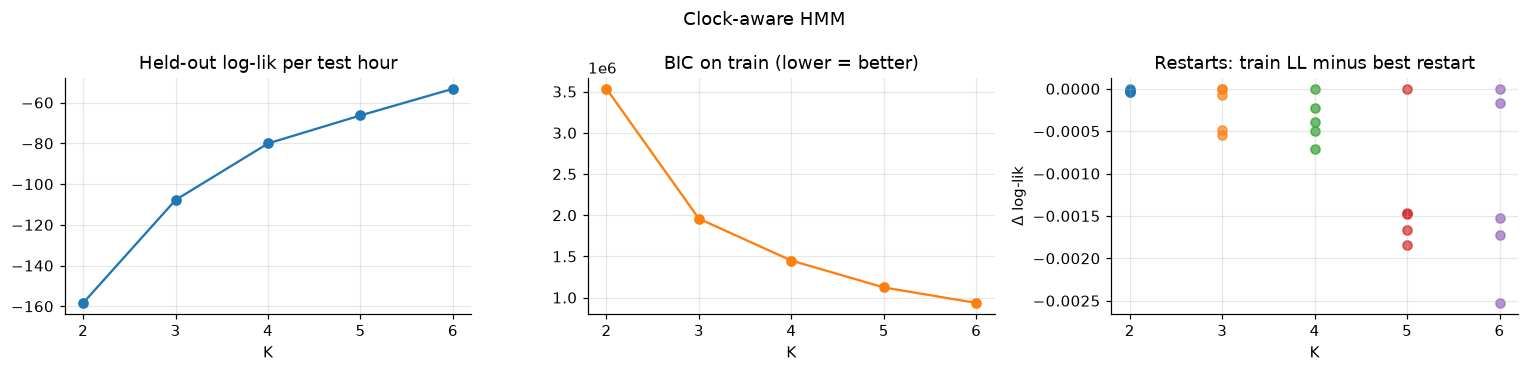

held-out LL/hour  naive (K=6): -145.4   clock baseline alone: -652.5   clock-aware (K=6): -53.2


In [17]:
B_tr, B_te = B_how[~is_test], B_how[is_test]
models_clock, runs_clock, summ_clock = run_sweep(
    fit_fn=lambda K, s: ClockAwarePoissonHMM(K, random_state=s).fit(X_tr, B_tr),
    score_fn=lambda m, part: m.score(X_tr, B_tr) if part == "train" else m.score(X_te, B_te),
    Ks=K_RANGE_CLOCK, F=len(FEATURES), T_train=len(X_tr), label="clock-aware")
K_clock = choose_K(summ_clock)
display(summ_clock.drop(columns=["train_ll"]))
print("BIC-optimal K:", summ_clock.BIC.idxmin(), "| elbow-chosen K:", K_clock)
plot_sweep(summ_clock, runs_clock, "Clock-aware HMM")

# Also useful for the report: how much does the clock alone explain? (log-lik of the K=1 'model' = baseline only)
base_te = poisson_log_emissions(X_te.astype(float), np.maximum(B_te, 1e-3)[:, None, :])[:, 0].sum()
print(f"held-out LL/hour  naive (K={K_naive}): {summ_naive.loc[K_naive, 'test_ll_per_hour']:.1f}   "
      f"clock baseline alone: {base_te / is_test.sum():.1f}   clock-aware (K={K_clock}): {summ_clock.loc[K_clock, 'test_ll_per_hour']:.1f}")

**A fair comparison.** The naive and clock-aware models describe *the same observations*, so their held-out log-likelihoods are directly comparable. The printout above also includes the "clock alone" model (Poisson at the hour-of-week mean, no hidden state). The clock-aware model fits far better: −53 per hour, against −145 for the naive model and −652 for the clock alone. So the hidden state adds information on top of the calendar. Two caveats: this is September, which was also used to choose $K$, and $K=6$ is the largest value we tried, so the best $K$ may be higher.

,UES_to_MID,MID_to_UES,within_UES,within_MID,round_trip,other,share of hours,member share (held out)
S0: avg ×0.15,0.11,0.12,0.16,0.18,0.17,0.14,0.06,0.91
S1: avg ×0.39,0.34,0.35,0.44,0.48,0.35,0.39,0.12,0.90
S2: avg ×0.68,0.63,0.68,0.76,0.80,0.55,0.68,0.18,0.88
S3: avg ×0.99,0.97,0.99,1.03,1.04,0.90,1.00,0.17,0.85
S4: avg ×1.33,1.36,1.35,1.28,1.27,1.38,1.34,0.28,0.83
S5: avg ×1.65,1.74,1.66,1.56,1.46,1.85,1.65,0.18,0.78


Transition matrix (rows = from, sorted states):


,S0: avg ×0.15,S1: avg ×0.39,S2: avg ×0.68,S3: avg ×0.99,S4: avg ×1.33,S5: avg ×1.65
S0: avg ×0.15,0.869,0.124,0.004,0.000,0.004,0.000
S1: avg ×0.39,0.062,0.811,0.121,0.005,0.000,0.000
S2: avg ×0.68,0.004,0.074,0.825,0.094,0.003,0.001
S3: avg ×0.99,0.000,0.005,0.089,0.792,0.112,0.003
S4: avg ×1.33,0.000,0.002,0.005,0.070,0.843,0.079
S5: avg ×1.65,0.000,0.001,0.002,0.004,0.131,0.863


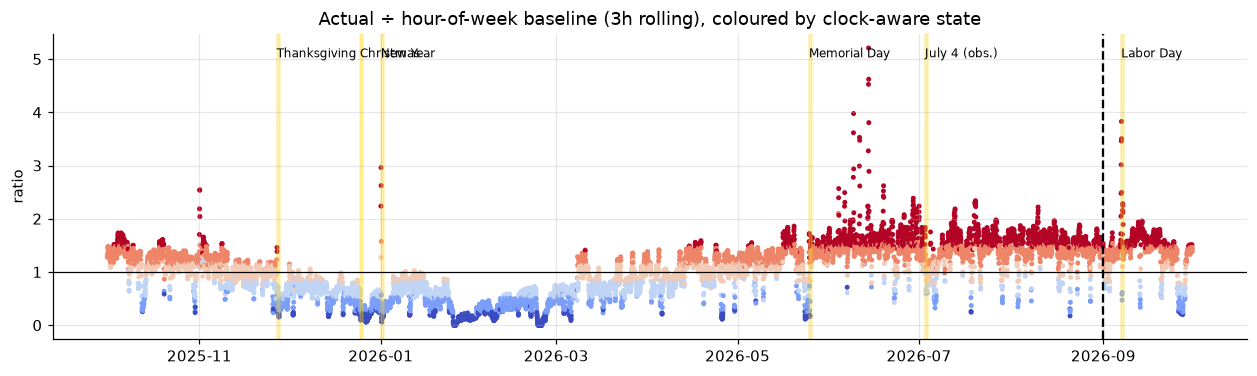

In [18]:
m_clock = models_clock[K_clock]
rank_clock = relabel_by(m_clock.multipliers_.mean(1))
mult_clock = m_clock.multipliers_[np.argsort(m_clock.multipliers_.mean(1))]
z_clock = rank_clock[m_clock.decode(X_all, B_how)]
names_clock = [f"S{k}: avg ×{mult_clock[k].mean():.2f}" for k in range(K_clock)]

tbl = pd.DataFrame(mult_clock, index=names_clock, columns=FEATURES)
tbl["share of hours"] = np.bincount(z_clock, minlength=K_clock) / len(z_clock)
tbl["member share (held out)"] = (pd.Series(members.to_numpy()).groupby(z_clock).sum() / pd.Series(total.to_numpy()).groupby(z_clock).sum()).reindex(range(K_clock)).to_numpy()
display(tbl.style.background_gradient(cmap="RdBu_r", subset=FEATURES, vmin=0, vmax=2).format("{:.2f}"))
print("Transition matrix (rows = from, sorted states):")
display(pd.DataFrame(m_clock.transmat_[np.ix_(np.argsort(m_clock.multipliers_.mean(1)), np.argsort(m_clock.multipliers_.mean(1)))],
                     index=names_clock, columns=names_clock).round(3))

ratio = pd.Series(X_all.sum(1) / B_how.sum(1), index=ALL_HOURS).rolling(3, center=True).mean()
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.scatter(ALL_HOURS, ratio, c=z_clock, cmap="coolwarm", s=5, vmin=0, vmax=K_clock - 1)
ax.axhline(1, color="k", lw=0.8)
for d, lbl in [("2025-11-27", "Thanksgiving"), ("2025-12-25", "Christmas"), ("2026-01-01", "New Year"),
               ("2026-05-25", "Memorial Day"), ("2026-07-03", "July 4 (obs.)"), ("2026-09-07", "Labor Day")]:
    if PERIOD_START <= pd.Timestamp(d) < PERIOD_END:
        ax.axvspan(pd.Timestamp(d), pd.Timestamp(d) + pd.Timedelta("1D"), color="gold", alpha=0.3); ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.92, lbl, fontsize=8)
ax.axvline(TEST_START, color="k", ls="--")
ax.set(title="Actual ÷ hour-of-week baseline (3h rolling), coloured by clock-aware state", ylabel="ratio")
plt.show()

**What we found.**
* **The states are levels relative to the clock**, with average multipliers from ×0.15 to ×1.65. Within a state, every ride type is scaled by a similar amount.
* **"Normal" is not the most common state.** Only 17% of hours are in the ×0.99 state; about 36% are below it and 46% above it.
* **No holiday state.** Round trips ran at 1.8× (Memorial Day) and 2.6× (Labor Day) their clock baseline while UES↔MID rides were below theirs, but MLK Day and Presidents' Day show no such round-trip rise, and no state combines low commuting with high round trips.
* **States persist for hours, not whole days.** The chance of staying in a state is 79–87% per hour, the average stretch is 5–7 hours and the median is 3–5 hours.

### Optional external validation: weather
Do the levels line up with weather we **never showed the model**? The cell below pulls hourly precipitation from the free Open-Meteo historical API. If you have no internet, it just skips.

In [19]:
weather = None
try:
    url = ("https://archive-api.open-meteo.com/v1/archive?latitude=40.75&longitude=-73.98"
           f"&start_date={PERIOD_START.date()}&end_date={(PERIOD_END - pd.Timedelta('1D')).date()}"
           "&hourly=precipitation,temperature_2m&timezone=America%2FNew_York")
    with urllib.request.urlopen(url, timeout=30) as r:
        w = json.load(r)["hourly"]
    weather = pd.DataFrame({"precip_mm": w["precipitation"], "temp_c": w["temperature_2m"]},
                           index=pd.to_datetime(w["time"])).reindex(ALL_HOURS)
except Exception as ex:
    print("weather download skipped:", ex)

if weather is not None:
    wz = weather.assign(state_clock=z_clock, state_naive=z_naive, raining=weather.precip_mm > 0.2)
    print("Clock-aware states vs weather (weather was never an input):")
    display(wz.groupby("state_clock").agg(hours=("raining", "size"), pct_hours_raining=("raining", "mean"),
                                     mean_precip_mm=("precip_mm", "mean"), mean_temp_c=("temp_c", "mean"))
              .set_axis(names_clock).round(3))
    print("Naive states vs weather (for contrast):")
    display(wz.groupby("state_naive").agg(pct_hours_raining=("raining", "mean"), mean_precip_mm=("precip_mm", "mean"))
              .set_axis(names_naive).round(3))

Clock-aware states vs weather (weather was never an input):


,hours,pct_hours_raining,mean_precip_mm,mean_temp_c
S0: avg ×0.15,550,0.295,0.511,-4.401
S1: avg ×0.39,1077,0.213,0.348,0.860
S2: avg ×0.68,1593,0.114,0.165,4.494
S3: avg ×0.99,1519,0.086,0.123,11.111
S4: avg ×1.33,2468,0.053,0.062,19.906
S5: avg ×1.65,1553,0.031,0.038,23.183


Naive states vs weather (for contrast):


,pct_hours_raining,mean_precip_mm
"S0: 409/h, most over-rep: round_trip",0.155,0.274
"S1: 1,554/h, most over-rep: within_MID",0.146,0.241
"S2: 3,718/h, most over-rep: within_MID",0.093,0.120
"S3: 6,549/h, most over-rep: within_UES",0.064,0.078
"S4: 9,748/h, most over-rep: UES_to_MID",0.057,0.067
"S5: 14,631/h, most over-rep: MID_to_UES",0.061,0.062


**What the weather shows.** The clock-aware states line up with weather: from the lowest to the highest state, rain falls from 30% to 3% of hours and the mean temperature rises from −4 °C to 23 °C. So the low states are **cold and wet**, not simply "rain": about 70% of hours in the lowest state are dry. Because the clock baseline is a year-round average, **season** is a large part of this. The naive model's states also vary with rain, but less (15.5% in the quietest state, about 6% in the two busiest).

## 7. Forecasting: both models and the baselines side by side
The clock-aware forecast is $\hat x_{t} = b_t \odot \big(P(z_t \mid x_{1:t-h})\, M\big)$: the calendar's expectation, scaled by where we think the regime is heading.

MAE at h = 1 hour ahead (rides/hour, test weeks; lower is better)


target,total,UES_to_MID,MID_to_UES,net_into_MID
method,,,,
24h ratio,898.0,8.0,7.7,8.8
activity-adjusted,844.4,7.5,7.9,9.6
clock-aware HMM,579.3,6.5,6.6,8.4
hour-of-week mean,2447.7,13.3,13.3,11.0
naive HMM,1912.3,22.3,20.7,21.4
persistence,1766.6,17.0,16.0,21.5


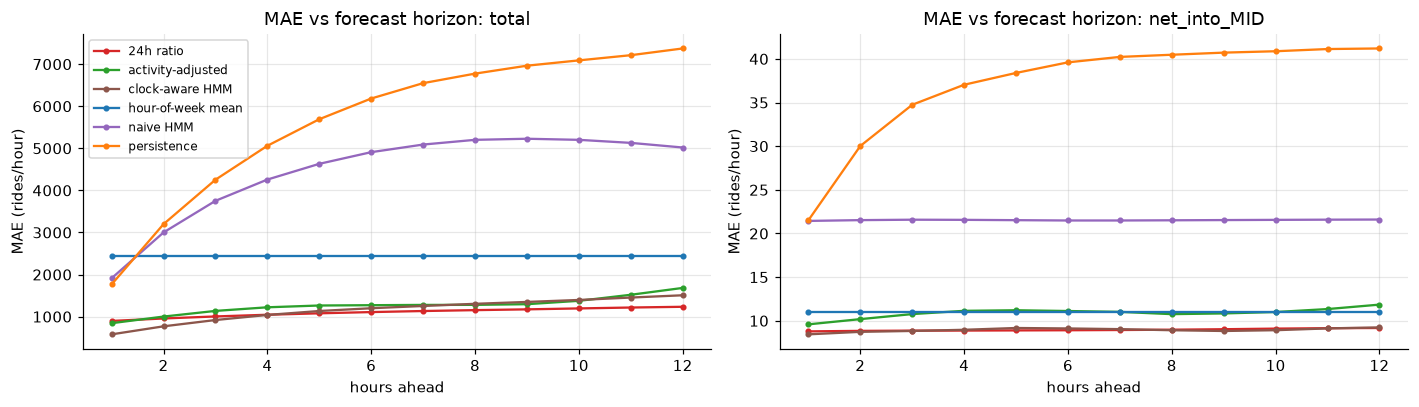

In [20]:
filt_clock = m_clock.filter(X_all, B_how)
forecasters["clock-aware HMM"] = lambda h: targets(B_how * hmm_forecast(filt_clock, m_clock.transmat_, lambda P: P @ m_clock.multipliers_, h))
res = evaluate(forecasters, HORIZONS)

print("MAE at h = 1 hour ahead (rides/hour, test weeks; lower is better)")
display(res[res.h == 1].pivot(index="method", columns="target", values="MAE")[list(actual)].round(1))

COLORS = {m: f"C{i}" for i, m in enumerate(forecasters)}   # fixed colour per method across panels
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, tgt in zip(ax, ["total", "net_into_MID"]):
    for name, g in res[res.target == tgt].groupby("method"):
        a.plot(g.h, g.MAE, "o-", ms=3, label=name, color=COLORS[name])
    a.set(title=f"MAE vs forecast horizon: {tgt}", xlabel="hours ahead", ylabel="MAE (rides/hour)")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**What we found** (September 2026).
* **Persistence** beats the hour-of-week mean at $h=1$ on total rides only (1,767 vs 2,448). It loses on both directions and on net flow, and gets much worse after that.
* The **hour-of-week mean** is flat across horizons, because it never looks at recent data.
* The **activity-adjusted** average is much better than the hour-of-week mean on total rides at every horizon. On net flow it is better at $h=1$ (9.6 vs 11.0) but slightly worse by $h=12$ (11.8 vs 11.0).
* The **24-hour ratio** is worse than the clock-aware HMM at $h=1$ (total 898 vs 579; net flow 8.8 vs 8.4), but better on total rides by $h=6$ (1,109 vs 1,200) and $h=12$ (1,234 vs 1,508). On net flow the two are about equal by $h=12$ (both 9.2).
* The **naive HMM** is close to persistence on total rides at $h=1$ (1,912 vs 1,767) and worse than the hour-of-week mean from $h=2$.
* The **clock-aware HMM** has the lowest error on every target at $h=1$. It has **not** returned to the baseline by $h=12$ (total MAE 1,508 vs 2,448; net flow 9.2 vs 11.0). On total rides activity-adjusted is slightly ahead at $h=9$ (1,296 vs 1,350).

This is one month, and $K$ was chosen on it. Section 8 is the proper test.

---
## 8. Full-year test: clock-aware HMM vs. the four baselines
Section 7 tests one month. Here every month from **Oct 2025 to Sep 2026** is a test month, and each is forecast by a model trained on **only the 12 months before it**. Nothing from the test month is used for fitting or tuning: the zones, baselines and $K$ are redone in every fold. $K$ is picked with the same elbow rule, but on the **last training month** (fit on the first 11), then the model is refit on all 12.

**Zones:** the Upper East Side (UES) and Midtown (MID) rectangles from section 3, with the station list rebuilt from each fold's training months.

**Two tasks**, scored on UES→MID and MID→UES rides per hour:
* **Noon:** at noon, forecast hours 12–23 of the same day.
* **Rolling:** for every hour, forecast it from $h=1..12$ hours earlier.

**Baselines:** hour-of-week mean, persistence (the last observed hour, held flat), activity-adjusted, and the 24-hour ratio (both ratios computed from UES→MID + MID→UES rides). The 24-hour ratio uses the same year-round clock baseline as the HMM but has no hidden state and no midnight reset. Its 24-hour window was chosen by hand to cover one daily cycle, not tuned on validation data, and we had already looked at this ratio on the same test year when we added it. The HMM sees all 6 ride types. Daylight-saving days are not scored.

**Is a difference real?** We bootstrap over whole **weeks**, because neighbouring days share weather and are not independent. This measures sampling noise within this one year only.

In [21]:
WF_START = pd.Timestamp(HISTORY_MONTHS[0] + "01")
WF_TESTS = pd.period_range(MONTHS[0], MONTHS[-1], freq="M")
DST_DATES = pd.to_datetime(["2024-11-03", "2025-03-09", "2025-11-02", "2026-03-08"])

# Both years as integer codes (station, station, hour): ~1 GB instead of many GB of strings
history, history_coords = load_rides(HISTORY_MONTHS)
history = history[(history.hour >= WF_START) & (history.hour < PERIOD_START)]
stations = pd.Index(pd.concat([history.s, history.e, rides.s, rides.e]).unique())
code = lambda col: np.concatenate([stations.get_indexer(d[col]) for d in (history, rides)]).astype(np.int32)
wf_s, wf_e = code("s"), code("e")
wf_h = np.concatenate([((d.hour - WF_START) // pd.Timedelta("1h")).to_numpy() for d in (history, rides)]).astype(np.int32)
wf_xy = station_coords[["start_lat", "start_lng"]].combine_first(history_coords[["start_lat", "start_lng"]]).reindex(stations).to_numpy()
print(history.groupby(history.hour.dt.to_period("M")).size().rename("history rides per month"))
print(f"{len(wf_s):,} rides, {len(stations):,} stations ({np.isnan(wf_xy[:, 0]).sum()} without coordinates)")
del history

def fold_counts(test):
    # Hourly (T, 6) ride-type counts for one fold's 12 training months + test month; zone stations use the training months only.
    start, test_start, end = (test - 12).start_time, test.start_time, (test + 1).start_time
    hours = pd.date_range(start, end, freq="h", inclusive="left"); T, n = len(hours), len(stations)
    off = int((start - WF_START) / pd.Timedelta("1h"))
    keep = (wf_h >= off) & (wf_h < off + T)
    s, e, t = wf_s[keep], wf_e[keep], wf_h[keep] - off
    train_hour = hours < test_start
    tr = train_hour[t]
    ends = np.bincount(s[tr], minlength=n) + np.bincount(e[tr], minlength=n)
    active = np.bincount(np.unique(s[tr].astype(np.int64) * 1000 + t[tr] // 24) // 1000, minlength=n)
    zone, (lat, lng) = np.zeros(n, int), wf_xy.T                  # 1 = UES, 2 = MID, 0 = outside
    for z, (lat0, lat1, lng0, lng1) in zip((1, 2), RECTS.values()):
        zone[(lat >= lat0) & (lat < lat1) & (lng >= lng0) & (lng < lng1) & (ends >= MIN_ENDPOINTS) & (active >= MIN_ACTIVE_DAYS)] = z
    a, b = zone[s], zone[e]
    typ = np.select([s == e, (a == 1) & (b == 2), (a == 2) & (b == 1), (a == 1) & (b == 1), (a == 2) & (b == 2)],
                    [4, 0, 1, 2, 3], 5)                            # same order as FEATURES
    return np.bincount(t.astype(np.int64) * 6 + typ, minlength=T * 6).reshape(T, 6).astype(float), (zone == 1).sum(), (zone == 2).sum()

t0 = time.perf_counter()
fold_data = {test: fold_counts(test) for test in WF_TESTS}
print(f"built {len(fold_data)} folds in {time.perf_counter() - t0:.0f}s")
del wf_s, wf_e, wf_h

loaded cache 202410_202509


hour
2024-10    5133307
2024-11    3696497
2024-12    2302858
2025-01    2119764
2025-02    2026077
2025-03    3158596
2025-04    3714220
2025-05    4311705
2025-06    4740549
2025-07    4964730
2025-08    5107407
2025-09    5271862
Freq: M, Name: history rides per month, dtype: int64
91,774,512 rides, 2,674 stations (101 without coordinates)


built 12 folds in 16s


In [22]:
HMM_, HOW_, PER_, ACT_, R24_ = "clock-aware HMM", "hour-of-week mean", "persistence", "activity-adjusted", "24h ratio"
WF_BASELINES = [HOW_, PER_, ACT_, R24_]
WF_METHODS = WF_BASELINES + [HMM_]

def run_fold(test, X, n_ues, n_mid):
    hours = pd.date_range((test - 12).start_time, (test + 1).start_time, freq="h", inclusive="left")
    is_te, is_va = hours >= test.start_time, (hours >= (test - 1).start_time) & (hours < test.start_time)
    is_tr = ~is_te; is_fit = is_tr & ~is_va
    key = hours.dayofweek * 24 + hours.hour
    clock = lambda mask: pd.DataFrame(X[mask]).groupby(key[mask]).mean().reindex(key).to_numpy()
    best = lambda K, mask, B: max((ClockAwarePoissonHMM(K, random_state=SEED + r).fit(X[mask], B[mask]) for r in range(N_RESTARTS)),
                                  key=lambda m: m.history_[-1])
    # choose K on the last training month, then refit on all 12
    B_fit, val_ll = clock(is_fit), {}
    for K in K_RANGE_CLOCK:
        m = best(K, is_fit, B_fit)
        val_ll[K] = m.score(X[is_tr], B_fit[is_tr]) - m.score(X[is_fit], B_fit[is_fit])
    K = choose_K(pd.Series(val_ll, name="test_ll").to_frame())
    B = clock(is_tr)
    m = best(K, is_tr, B); filt = m.filter(X, B)

    dst = hours.normalize().isin(DST_DATES)
    Y, te, rows = X[:, :2], np.flatnonzero(is_te & ~dst), []
    fit_days = is_tr & ~dst                                       # days used for the activity-adjusted profile
    for h in HORIZONS:
        pred = {HOW_: B[te, :2], PER_: Y[te - h], ACT_: activity_adjusted(Y, h, fit_days, hours)[te], R24_: ratio_24h(Y, B[:, :2], h)[te],
                HMM_: (B[te] * (filt[te - h] @ np.linalg.matrix_power(m.transmat_, h) @ m.multipliers_))[:, :2]}
        for name, p in pred.items():
            d, hr = p - Y[te], hours[te]
            rows.append(pd.DataFrame(dict(method=name, h=h, time=hr, abs=np.abs(d).sum(1), sq=(d ** 2).sum(1),
                                          net=np.abs(d[:, 0] - d[:, 1]), pred=p.sum(1), actual=Y[te].sum(1))))
    info = dict(test=str(test), K=K, stations_UES=n_ues, stations_MID=n_mid,
                multipliers=np.round(np.sort(m.multipliers_.mean(1)), 2).tolist(), filt_nan=bool(np.isnan(filt).any()))
    return pd.concat(rows, ignore_index=True), info

from joblib import Parallel, delayed
t0 = time.perf_counter()
done = Parallel(n_jobs=WF_JOBS)(delayed(run_fold)(test, *v) for test, v in fold_data.items())
wf = pd.concat([r for r, _ in done], ignore_index=True)
wf_info = pd.DataFrame([i for _, i in done])
assert not wf.isna().any().any() and not wf_info.filt_nan.any()
wf["month"], wf["week"], wf["date"] = wf.time.dt.to_period("M"), wf.time.dt.to_period("W"), wf.time.dt.normalize()
print(f"{len(done)} folds in {time.perf_counter() - t0:.0f}s, {wf.date.nunique()} test days")
display(wf_info.drop(columns="filt_nan").set_index("test"))

# Noon task: hour 12 is h=1 from 11:00-11:59, ..., hour 23 is h=12, so it is a subset of the rolling rows
noon = wf[wf.time.dt.hour - wf.h == 11]

12 folds in 119s, 363 test days


,K,stations_UES,stations_MID,multipliers
test,,,,
2025-10,5,57,75,"[0.31, 0.59, 0.89, 1.22, 1.44]"
2025-11,5,57,75,"[0.31, 0.59, 0.9, 1.22, 1.46]"
2025-12,5,57,73,"[0.32, 0.6, 0.9, 1.23, 1.47]"
2026-01,5,57,73,"[0.28, 0.58, 0.89, 1.23, 1.47]"
2026-02,5,57,73,"[0.21, 0.53, 0.86, 1.22, 1.47]"
2026-03,6,57,74,"[0.14, 0.38, 0.66, 0.95, 1.28, 1.52]"
2026-04,5,56,74,"[0.15, 0.4, 0.72, 1.08, 1.43]"
2026-05,5,52,70,"[0.15, 0.41, 0.73, 1.12, 1.44]"
2026-06,6,52,69,"[0.14, 0.38, 0.66, 0.94, 1.27, 1.52]"


### Noon task: full-year results
Every method is scored on the same cells (test days × 12 hours × 2 directions). **vs X** columns are the % error reduction of that row relative to baseline X; positive = better than X. **bias** is total predicted ÷ total actual − 1 over the whole year; a small number can hide opposite errors in different seasons, so we also show it by season below.

In [23]:
def metrics(g):
    n = len(g)
    return pd.Series({"MAE": g["abs"].sum() / (2 * n), "RMSE": np.sqrt(g["sq"].sum() / (2 * n)), "net MAE": g["net"].mean(),
                      "bias %": 100 * (g.pred.sum() / g.actual.sum() - 1)})

def table(df, by):
    return df.groupby(["method", *by])[["abs", "sq", "net", "pred", "actual"]].apply(metrics)

t = table(noon, []).loc[WF_METHODS]
for b in WF_BASELINES:
    t[f"MAE vs {b}"] = 100 * (1 - t["MAE"] / t.loc[b, "MAE"])
print(f"NOON (mean actual {noon[noon.method == HMM_].actual.mean() / 2:.0f} rides per hour and direction)"); display(t.round(1))

SEASON = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring", 6: "summer", 7: "summer", 8: "summer"}
noon = noon.assign(season=noon.time.dt.month.map(SEASON).fillna("fall"))
print("Noon bias % by season"); display(table(noon, ["season"])["bias %"].unstack("season").loc[WF_METHODS].round(0))

NOON (mean actual 35 rides per hour and direction)


,MAE,RMSE,net MAE,bias %,MAE vs hour-of-week mean,MAE vs persistence,MAE vs activity-adjusted,MAE vs 24h ratio
method,,,,,,,,
hour-of-week mean,15.7,22.6,10.4,1.4,0.0,22.5,-84.3,-71.8
persistence,20.2,33.1,19.4,-16.9,-29.0,0.0,-137.8,-121.7
activity-adjusted,8.5,13.2,8.8,-0.1,45.7,58.0,0.0,6.8
24h ratio,9.1,14.6,8.5,0.3,41.8,54.9,-7.2,0.0
clock-aware HMM,9.1,14.5,8.9,1.2,41.7,54.8,-7.5,-0.2


Noon bias % by season


season,fall,spring,summer,winter
method,,,,
hour-of-week mean,-11.0,-5.0,-25.0,125.0
persistence,-17.0,-17.0,-12.0,-28.0
activity-adjusted,-1.0,-0.0,-2.0,6.0
24h ratio,1.0,-0.0,-1.0,2.0
clock-aware HMM,-2.0,-3.0,-3.0,34.0


### Rolling task: full-year results by horizon

ROLLING MAE


h,1,2,3,6,9,12,mean
method,,,,,,,
hour-of-week mean,12.18,12.18,12.18,12.18,12.18,12.18,12.18
persistence,12.42,18.54,23.39,31.22,35.27,38.37,29.69
activity-adjusted,6.24,7.01,7.92,9.83,10.15,11.77,9.41
24h ratio,6.65,6.93,7.15,7.60,7.93,8.24,7.59
clock-aware HMM,5.73,6.25,6.74,7.85,8.13,8.67,7.58


ROLLING net MAE


h,1,2,3,6,9,12,mean
method,,,,,,,
hour-of-week mean,9.40,9.40,9.40,9.40,9.40,9.40,9.40
persistence,16.18,22.49,26.07,29.54,30.66,30.81,27.87
activity-adjusted,7.16,7.69,8.43,9.54,8.95,9.51,8.92
24h ratio,7.07,7.21,7.28,7.38,7.48,7.68,7.40
clock-aware HMM,6.84,7.08,7.27,7.81,7.66,7.89,7.56


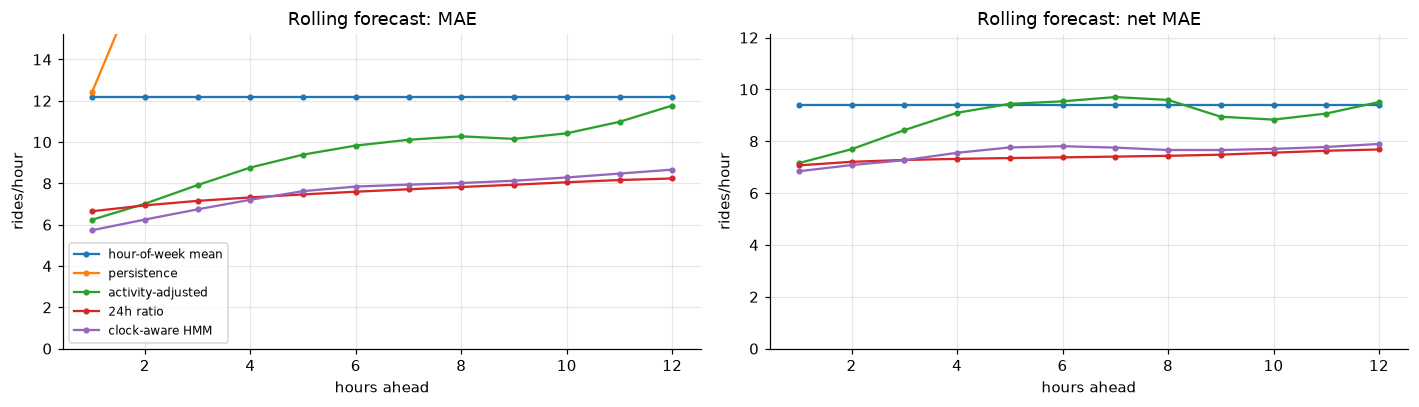

In [24]:
roll = table(wf, ["h"]).reset_index()
for metric in ["MAE", "net MAE"]:
    p = roll.pivot(index="method", columns="h", values=metric).loc[WF_METHODS]
    p["mean"] = p.mean(axis=1)
    print(f"ROLLING {metric}"); display(p[[1, 2, 3, 6, 9, 12, "mean"]].round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, metric in zip(ax, ["MAE", "net MAE"]):
    for i, name in enumerate(WF_METHODS):
        q = roll[roll.method == name]; a.plot(q.h, q[metric], "o-", ms=3, color=f"C{i}", label=name)
    others = roll[roll.method != PER_][metric]
    a.set(title=f"Rolling forecast: {metric}", xlabel="hours ahead", ylabel="rides/hour", ylim=(0, others.max() * 1.25))   # persistence runs off the top
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Month by month

NOON MAE by month


method,hour-of-week mean,persistence,activity-adjusted,24h ratio,clock-aware HMM
month,,,,,
2025-10,12.9,25.9,9.0,9.8,8.4
2025-11,10.5,18.8,8.9,9.0,8.7
2025-12,17.5,11.7,5.7,6.2,7.6
2026-01,20.4,10.5,4.8,5.1,8.9
2026-02,23.3,7.8,3.4,4.5,6.4
2026-03,12.4,16.4,6.7,7.9,7.4
2026-04,11.2,24.3,8.6,10.3,8.6
2026-05,15.4,25.6,10.0,10.5,10.6
2026-06,17.2,24.6,11.2,10.5,10.6


months won: {'activity-adjusted': 7, 'clock-aware HMM': 4, '24h ratio': 1}
ROLLING, MEAN OVER H MAE by month


method,hour-of-week mean,persistence,activity-adjusted,24h ratio,clock-aware HMM
month,,,,,
2025-10,10.3,37.4,9.2,8.7,7.4
2025-11,8.5,27.7,8.2,7.4,7.3
2025-12,14.0,16.7,7.0,5.8,7.0
2026-01,15.4,15.2,6.5,4.5,7.7
2026-02,18.3,11.0,5.5,4.1,6.3
2026-03,9.6,23.7,6.9,6.9,6.0
2026-04,8.7,34.4,9.0,8.0,7.3
2026-05,12.1,37.2,9.7,8.0,8.4
2026-06,13.4,39.2,18.7,8.4,8.4


months won: {'clock-aware HMM': 8, '24h ratio': 4}


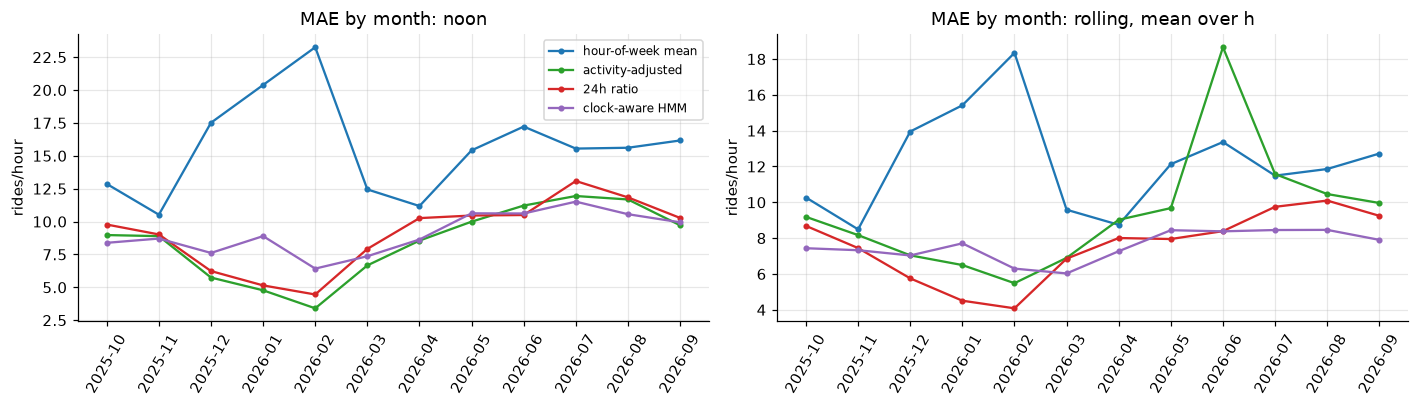

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, (task, df) in zip(ax, [("noon", noon), ("rolling, mean over h", wf)]):
    p = table(df, ["month"])["MAE"].unstack("method")[WF_METHODS]
    print(f"{task.upper()} MAE by month"); display(p.round(1))
    print("months won:", p.idxmin(axis=1).value_counts().to_dict())
    for i, name in enumerate(WF_METHODS):
        if name != PER_:
            a.plot(p.index.astype(str), p[name], "o-", ms=3, color=f"C{i}", label=name)
    a.set(title=f"MAE by month: {task}", ylabel="rides/hour"); a.tick_params(axis="x", rotation=60)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Are the differences real? Week-block bootstrap
% error reduction of the HMM relative to each baseline, with a 95% interval. Positive = HMM better. An interval that contains 0 means we can't tell them apart on this year of data.

In [26]:
def boot(df, base, col, reps=4000):
    w = df[df.method.isin([HMM_, base])].groupby(["week", "method"])[col].sum().unstack()
    a, b = w[HMM_].to_numpy(), w[base].to_numpy()
    idx = np.random.default_rng(SEED).integers(0, len(w), (reps, len(w)))
    lo, hi = np.percentile(100 * (1 - a[idx].sum(1) / b[idx].sum(1)), [2.5, 97.5])
    return f"{100 * (1 - a.sum() / b.sum()):+.1f} [{lo:+.1f}, {hi:+.1f}]" + ("" if lo > 0 or hi < 0 else " n.s.")

rows = []
for task, df in {"noon": noon, **{f"rolling h={h}": wf[wf.h == h] for h in (1, 3, 6, 12)}}.items():
    for label, col in [("MAE", "abs"), ("net MAE", "net")]:
        rows.append({"task": task, "metric": label, **{f"vs {b}": boot(df, b, col) for b in WF_BASELINES}})
display(pd.DataFrame(rows).set_index(["task", "metric"]))

vs hour-of-week mean        vs persistence  \
task         metric                                                
noon         MAE      +41.7 [+36.0, +47.0]  +54.8 [+49.8, +58.6]   
             net MAE  +14.2 [+10.4, +18.3]  +54.1 [+50.3, +57.0]   
rolling h=1  MAE      +52.9 [+47.5, +58.2]  +53.8 [+50.5, +56.5]   
             net MAE  +27.2 [+21.9, +32.8]  +57.7 [+55.2, +59.7]   
rolling h=3  MAE      +44.6 [+39.0, +50.0]  +71.2 [+68.3, +73.3]   
             net MAE  +22.7 [+18.0, +27.7]  +72.1 [+69.8, +73.9]   
rolling h=6  MAE      +35.6 [+29.8, +40.9]  +74.9 [+71.8, +77.1]   
             net MAE  +16.9 [+12.2, +21.7]  +73.6 [+71.0, +75.4]   
rolling h=12 MAE      +28.9 [+24.3, +33.0]  +77.4 [+74.2, +79.7]   
             net MAE  +16.0 [+12.6, +19.5]  +74.4 [+71.7, +76.3]   

                         vs activity-adjusted             vs 24h ratio  
task         metric                                                     
noon         MAE      -7.5 [-17.3, +0.2] n.s.   -0.2 [-9.7, +7.0] n.s.  
             net MAE   -1.4 [-6.6, +2.8] n.s.        -4.8 [-9.7, -0.8]  
rolling h=1  MAE           +8.1 [+3.1, +12.5]      +13.8 [+8.9, +18.0]  
             net MAE        +4.4 [+1.8, +6.7]        +3.2 [+0.5, +5.8]  
rolling h=3  MAE          +14.8 [+7.4, +22.2]  +5.7 [-1.3, +11.5] n.s.  
             net MAE      +13.8 [+9.2, +18.2]   +0.1 [-4.3, +4.1] n.s.  
rolling h=6  MAE          +20.2 [+9.5, +30.8]  -3.3 [-13.0, +4.2] n.s.  
             net MAE     +18.2 [+11.2, +25.1]       -5.8 [-12.2, -0.8]  
rolling h=12 MAE         +26.4 [+18.4, +35.4]  -5.2 [-17.5, +4.1] n.s.  
             net MAE     +17.0 [+14.4, +19.6]   -2.8 [-9.6, +2.5] n.s.

### Where does the HMM beat the ratio baselines?
Activity-adjusted resets at midnight, and early in the day its ratio rests on very few rides. Splitting the rolling forecasts by **how many hours of the target day had been seen** when the forecast was issued shows whether the HMM's advantage is general or comes from those hours.

In [27]:
seen = (wf.time.dt.hour - wf.h + 1).clip(lower=0)
bins = pd.cut(seen, [-1, 0, 3, 6, 11, 23], labels=["0", "1-3", "4-6", "7-11", "12+"]).rename("hours of day seen")
by_seen = wf.groupby([bins, "method"], observed=True)[["abs", "net"]].mean().assign(abs=lambda d: d["abs"] / 2)
for col, label in [("abs", "MAE"), ("net", "net MAE")]:
    print(f"ROLLING {label} by hours of the target day already seen"); display(by_seen[col].unstack("method")[WF_METHODS].round(1))

ROLLING MAE by hours of the target day already seen


method,hour-of-week mean,persistence,activity-adjusted,24h ratio,clock-aware HMM
hours of day seen,,,,,
0,5.6,31.5,5.7,3.9,4.0
1-3,11.0,24.6,13.9,7.3,7.7
4-6,16.0,35.0,15.8,10.5,10.5
7-11,17.9,32.0,10.5,11.0,10.6
12+,13.2,26.0,7.3,7.4,7.4


ROLLING net MAE by hours of the target day already seen


method,hour-of-week mean,persistence,activity-adjusted,24h ratio,clock-aware HMM
hours of day seen,,,,,
0,6.0,24.3,6.2,4.5,4.6
1-3,9.3,18.3,11.4,7.1,7.5
4-6,12.2,21.9,12.5,9.5,9.6
7-11,12.2,48.8,9.8,9.8,9.8
12+,9.4,22.5,8.2,7.6,7.9


### Reading the full-year results
* **Hour-of-week mean and persistence:** the HMM beats both at every horizon shown and at noon, and every interval excludes 0. Its total-count error is 29-53% below the hour-of-week mean.
* **Activity-adjusted, noon:** the HMM does **not** beat it. It is 7% worse on counts and 1% worse on net flow; neither difference can be told apart from 0.
* **Activity-adjusted, rolling:** the HMM is better at every horizon shown (8-26% on counts, 4-18% on net flow), and every interval excludes 0.
* **On counts, that rolling win comes from the early hours of the day.** With 7 or more hours of the day already seen, the two are about tied (on net flow a small HMM lead remains at 12+ hours). The HMM wins clearly when little of the day has been seen, where this baseline resets to 1 or uses a ratio based on few rides. The 24-hour ratio, which also carries the current level across midnight, does about as well as the HMM in those early hours. That points to carrying the level forward as the main reason for this win.
* **24-hour ratio:** overall the two are tied (counts 7.58 vs 7.59, net flow 7.56 vs 7.40 for the HMM and the ratio, averaged over horizons). The HMM is better **1 hour ahead** (14% on counts, 3% on net flow; both intervals exclude 0). The ratio is better on **net flow at noon** (5%) and **6 hours ahead** (6%). Counts at noon and at 3, 6 and 12 hours can't be told apart. By month the HMM wins most of the rolling task and the ratio wins winter (Dec–Feb) clearly.
* **Season:** the HMM's noon forecast is about 34% too high in winter and slightly low in the other seasons, so the near-zero yearly bias is winter cancelling the rest. A likely reason, which we did not isolate, is that the clock baseline is a 12-month average: a forecast that drifts back toward an average state drifts up in winter.
* **Do we need a hidden state?** For 1-hour-ahead forecasts it beats a 24-hour ratio. Over all horizons it does not, so on this year of data a hidden state is **not needed** to reach this overall accuracy. In a separate check (not in this notebook) a 3-hour window was slightly better than the HMM 1 hour ahead (5.46 vs 5.73) but worse from 3 hours ahead (7.30 vs 6.74), so the HMM's advantage is that one model does well at both short and long horizons.
* **States:** in every fold the average multipliers are spread out from low to high, so these are again levels.
* **Limits:** one test year and one pair of neighbourhoods; the intervals don't cover year-to-year variation; many comparisons are shown without a multiple-testing correction; no trip-duration filter.

## 9. Convergence and scalability
The guidelines ask: *was training stable, and would more data help?*

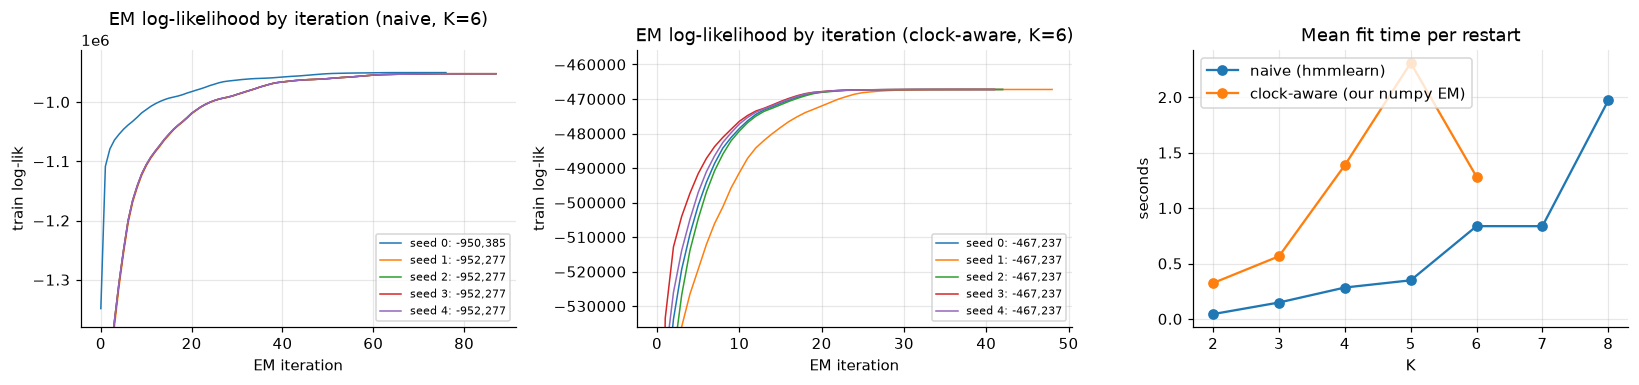

mean_iters  ll_spread_across_seeds
model       K                                    
clock-aware 2        12.0                     0.0
            3        20.0                     0.0
            4        48.2                     0.0
            5        79.8                     0.0
            6        43.8                     0.0
naive       2        13.0                     0.0
            3        31.0                     0.0
            4        45.0                   444.0
            5        43.2                   349.8
            6        85.8                  1891.6
            7        71.0                 80591.1
            8       144.6                 52473.3

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, runs, K, t in [(ax[0], runs_naive, K_naive, f"naive, K={K_naive}"), (ax[1], runs_clock, K_clock, f"clock-aware, K={K_clock}")]:
    for _, r in runs[runs.K == K].iterrows():
        a.plot(r.history, lw=1, label=f"seed {r.restart}: {r.history[-1]:,.0f}")
    a.set(title=f"EM log-likelihood by iteration ({t})", xlabel="EM iteration", ylabel="train log-lik"); a.legend(fontsize=7)
    lo = min(r.history[min(3, len(r.history) - 1)] for _, r in runs[runs.K == K].iterrows())
    a.set_ylim(bottom=lo)
for runs, lbl in [(runs_naive, "naive (hmmlearn)"), (runs_clock, "clock-aware (our numpy EM)")]:
    ax[2].plot(runs.groupby("K").seconds.mean(), "o-", label=lbl)
ax[2].set(title="Mean fit time per restart", xlabel="K", ylabel="seconds"); ax[2].legend()
plt.tight_layout(); plt.show()

conv = pd.concat([r.assign(model=n) for n, r in [("naive", runs_naive), ("clock-aware", runs_clock)]])
display(conv.groupby(["model", "K"]).agg(mean_iters=("iters", "mean"), ll_spread_across_seeds=("train_ll", lambda s: s.max() - s.min())).round(1))

**Talking points.**
* **Monotone curves:** EM never decreases the likelihood. Our clock-aware implementation asserts this on every fit.
* **Spread across seeds:** different restarts ending at different log-likelihoods is the local-optima problem, and it's why we use restarts. The spread does not simply grow with K: for the naive model it jumps at K=7 and 8, and for the clock-aware model it is 0.0 at every K.
* **Cost:** each EM iteration is $O(TK^2 + TKF)$, linear in the number of hours. Adding more months is cheap computationally. The expensive part is *preprocessing* tens of millions of rides, not the HMM. With ~48 training weeks the hour-of-week baseline has ~48 samples per cell, but those samples span every season. So the baseline is a year-round average, and seasonal deviations from it are left for the clock-aware model's hidden state to explain.

## 10. Limitations and alternative explanations (for the report)
* **Trips ≠ demand.** An empty station records *zero* departures even if 30 people wanted a bike (censored demand). Our counts understate demand exactly where rebalancing matters most. The real-time GBFS station-status feed would fix this.
* **Zones are two hand-drawn rectangles.** They cover one pair of neighbourhoods, hourly counts between them are small and noisy, and "residential" and "job centre" are assumptions about the areas. Five of the 54 UES stations are actually west of Central Park.
* **The states are levels, not kinds of riding.** "Other" is 93% of rides, but it is not the main cause: in a separate check (not in this notebook) replacing it with rides touching the two zones, or dropping it, gave nearly the same multipliers and slightly worse rolling forecasts over all horizons.
* **Overdispersion.** Real counts vary more than a Poisson allows, which pushes BIC toward more states. A negative-binomial emission would be the principled fix.
* **Time-homogeneous transitions** (naive model). This probably contributes to its losing to the clock, though we did not test it separately. The clock-aware model brings the clock in through the emissions. An alternative would be letting $A$ depend on the hour.
* **Conditional independence of ride types given the state.** Leftover correlation (e.g. weather hitting all types at once) violates it. The clock-aware model partially absorbs this, since one state scales all types.
* **Scope.** One year, one city-wide state. The hour-of-week baseline averages over all seasons and includes holidays (e.g. Memorial Day sits in "Monday"), so part of what the clock-aware states capture is *season*, not just day-to-day deviations.
* **Alternative explanations for the states:** a low state could be cold, rain, season, a holiday, a transit disruption, or a data outage. Season, temperature and rain are mixed together in our weather check, so it can't separate them.

## 11. Conclusion
* The **naive model** found 6 states that are busyness levels, from about 410 to 14,630 rides per hour. Using ride types did not produce direction or leisure states, and member share (0.81–0.86 in every state) does not support such a reading.
* The **clock-aware model** beat the hour-of-week mean at $h=1$ by about 24% on net flow into Midtown in September, and by 27% over the full year (section 8). Its lowest state coincided with rain in 30% of hours, against 3% for its highest, and is also much colder.
* **Against the activity-adjusted average** over the full year, it does not win at noon (7% worse on counts, not distinguishable from 0). It wins the rolling task by 8–26% on counts, mainly from forecasts made early in the day.
* **Against a 24-hour ratio** (no hidden state, no midnight reset) it is better 1 hour ahead (14% on counts, 3% on net flow), tied on counts at noon and at 3, 6 and 12 hours, and worse on net flow at noon and 6 hours ahead (5–6%). Averaged over horizons the two are about equal on counts.
* **Main takeaway for Lyft:** the hidden states capture how busy riding is relative to normal, and they line up with weather and season. Knowing that level helps forecast UES↔Midtown flow: one model is competitive from 1 to 12 hours ahead and is best at 1 hour. We did not find trip-purpose regimes, and beyond 1 hour ahead a simple 24-hour ratio did about as well, so most of the gain comes from tracking the current level rather than from the hidden state itself.

## References
* Citi Bike System Data: https://citibikenyc.com/system-data
* hmmlearn documentation: https://hmmlearn.readthedocs.io
* Open-Meteo Historical Weather API: https://open-meteo.com